# AI-305 Introduction to Machine Learning 

# NBA Player Performance Analysis 

## Data Exploration (Phase 1)

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
import kagglehub
import math
from sklearn.model_selection import KFold, cross_validate, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import LabelEncoder 
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy import stats

from sklearn.manifold import TSNE

c:\Users\sonso\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Loading and Reading Data

In [2]:
#Downloading the dataset from Kaggle
path = kagglehub.dataset_download('eduardopalmieri/nba-player-stats-season-2425')
print(path)

C:\Users\sonso\.cache\kagglehub\datasets\eduardopalmieri\nba-player-stats-season-2425\versions\37


In [44]:
# Loading and Reading Data 
data = pd.read_csv(path + '/database_24_25.csv')
data.head(5)

,Player,Tm,Opp,Res,MP,FG,FGA,FG%,3P,3PA,...,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,GmSc,Data
0,Jayson Tatum,BOS,NYK,W,30.30,14,18,0.778,8,11,...,4,4,10,1,1,1,1,37,38.1,2024-10-22
1,Anthony Davis,LAL,MIN,W,37.58,11,23,0.478,1,3,...,13,16,4,1,3,1,1,36,34.0,2024-10-22
2,Derrick White,BOS,NYK,W,26.63,8,13,0.615,6,10,...,3,3,4,1,0,0,1,24,22.4,2024-10-22
3,Jrue Holiday,BOS,NYK,W,30.52,7,9,0.778,4,6,...,2,4,4,1,0,0,2,18,19.5,2024-10-22
4,Miles McBride,NYK,BOS,L,25.85,8,10,0.800,4,5,...,0,0,2,0,0,1,1,22,17.8,2024-10-22


In [5]:
with pd.option_context('display.max_columns', None):
    print(data.head(5))

          Player   Tm  Opp Res     MP  FG  FGA    FG%  3P  3PA    3P%  FT  \
0   Jayson Tatum  BOS  NYK   W  30.30  14   18  0.778   8   11  0.727   1   
1  Anthony Davis  LAL  MIN   W  37.58  11   23  0.478   1    3  0.333  13   
2  Derrick White  BOS  NYK   W  26.63   8   13  0.615   6   10  0.600   2   
3   Jrue Holiday  BOS  NYK   W  30.52   7    9  0.778   4    6  0.667   0   
4  Miles McBride  NYK  BOS   L  25.85   8   10  0.800   4    5  0.800   2   

   FTA    FT%  ORB  DRB  TRB  AST  STL  BLK  TOV  PF  PTS  GmSc        Data  
0    2  0.500    0    4    4   10    1    1    1   1   37  38.1  2024-10-22  
1   15  0.867    3   13   16    4    1    3    1   1   36  34.0  2024-10-22  
2    2  1.000    0    3    3    4    1    0    0   1   24  22.4  2024-10-22  
3    0  0.000    2    2    4    4    1    0    0   2   18  19.5  2024-10-22  
4    3  0.667    0    0    0    2    0    0    1   1   22  17.8  2024-10-22  


In [4]:
#Shape of the data
print("Shape of the data:", data.shape)
print("\nColumns (Features) in the data:", data.columns.tolist())
print('-'*50)
data.info()

Shape of the data: (16512, 25)

Columns (Features) in the data: ['Player', 'Tm', 'Opp', 'Res', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'GmSc', 'Data']
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  16512 non-null  object 
 1   Tm      16512 non-null  object 
 2   Opp     16512 non-null  object 
 3   Res     16512 non-null  object 
 4   MP      16512 non-null  float64
 5   FG      16512 non-null  int64  
 6   FGA     16512 non-null  int64  
 7   FG%     16512 non-null  float64
 8   3P      16512 non-null  int64  
 9   3PA     16512 non-null  int64  
 10  3P%     16512 non-null  float64
 11  FT      16512 non-null  int64  
 12  FTA     16512 non-null  int64  
 13  FT%     16512 non-null  float64
 14  ORB 

#### Insights 1: Data Shape
Number of Samples (Rows): 16512

Number of Features (Columns): 25

DataTypes: 5 Strings, 20 Numerical

### Statistics (correlation, nuls, duplicates, and types)

In [5]:
data.describe()

,MP,FG,FGA,FG%,3P,3PA,3P%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,GmSc
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,22.405259,3.848958,8.271742,0.427527,1.250061,3.477955,0.263719,1.572917,2.016897,0.417737,1.027253,3.071827,4.099079,2.453852,0.769985,0.468084,1.273861,1.749152,10.520894,8.575109
std,10.896645,3.255864,6.071434,0.254938,1.523651,3.151726,0.286271,2.233374,2.688863,0.435771,1.371552,2.717525,3.478652,2.613505,0.991039,0.833377,1.428819,1.436416,8.829493,7.821577
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-7.600000
25%,14.427500,1.000000,4.000000,0.286000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,3.000000,2.400000
50%,23.430000,3.000000,7.000000,0.444000,1.000000,3.000000,0.250000,1.000000,1.000000,0.333000,1.000000,2.000000,3.000000,2.000000,0.000000,0.000000,1.000000,2.000000,9.000000,7.100000
75%,31.322500,6.000000,12.000000,0.571000,2.000000,5.000000,0.500000,2.000000,3.000000,1.000000,2.000000,4.000000,6.000000,4.000000,1.000000,1.000000,2.000000,3.000000,16.000000,13.300000
max,50.480000,22.000000,38.000000,1.000000,10.000000,20.000000,1.000000,18.000000,26.000000,1.000000,12.000000,23.000000,28.000000,22.000000,8.000000,10.000000,11.000000,6.000000,60.000000,54.200000


Numerical Features: ['MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'GmSc']
Categorical Features: ['Player', 'Tm', 'Opp', 'Res', 'Data']


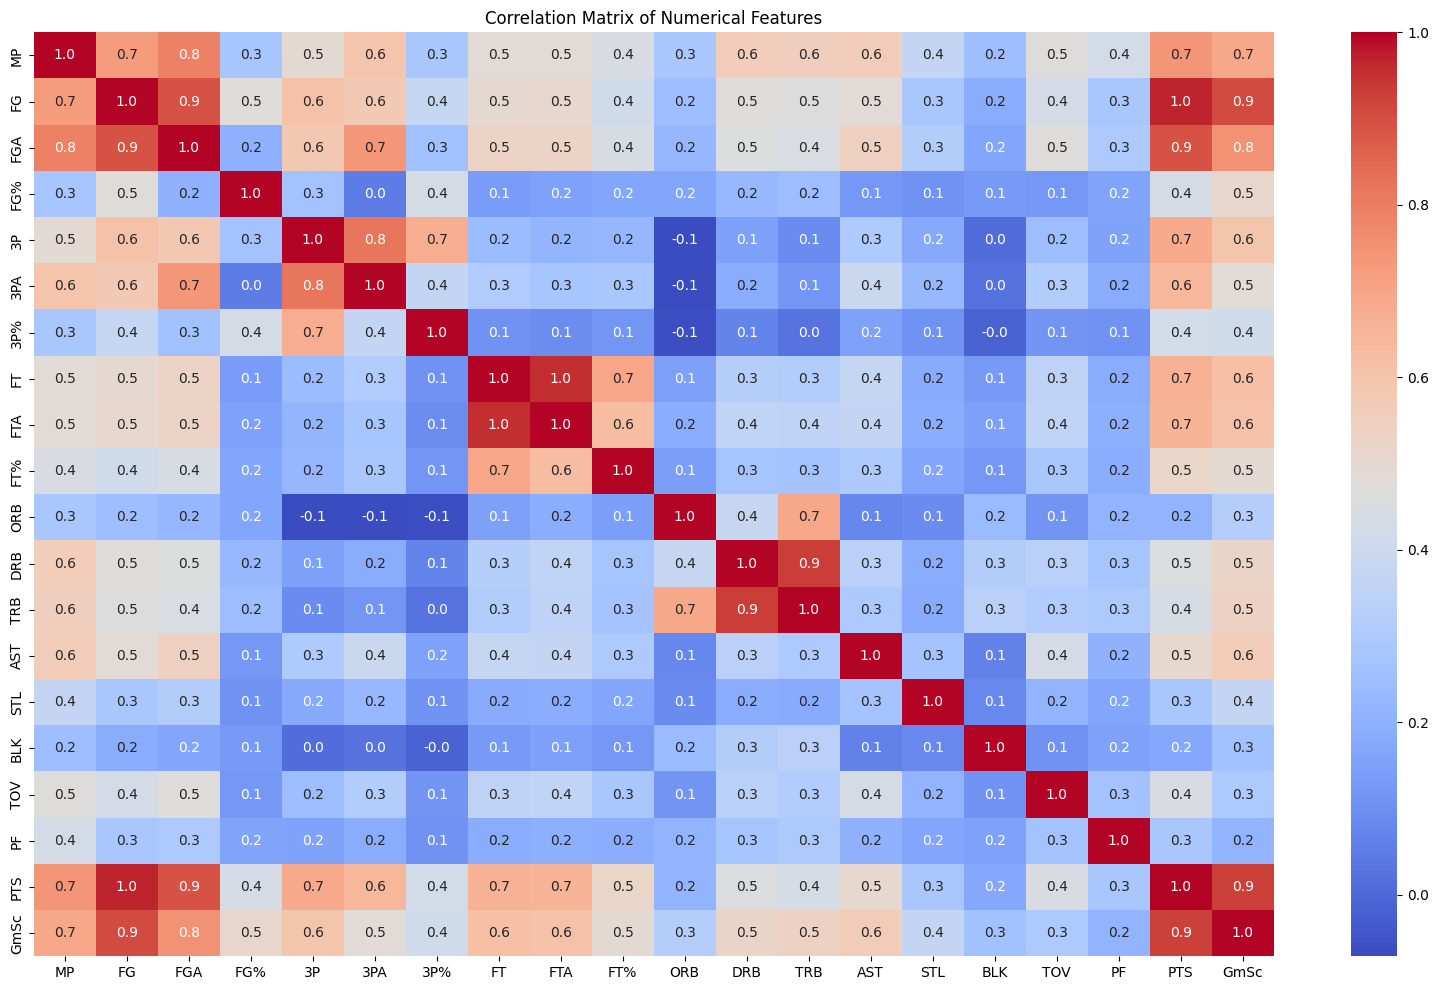

In [6]:
# Identifying Numerical and Categorical Features
numerical_features = data.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = data.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

# Correlation Matrix
plt.figure(figsize=(20, 12))
sns.heatmap(data[numerical_features].corr(), annot=True, fmt=".1f", cmap='coolwarm')
plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [7]:
# Missing Values?
missing_values = data.isnull().sum()
print("Missing Values in each column:\n", missing_values)

#Finding Duplicates
duplicates = data.duplicated().sum()
print("Number of duplicate rows:", duplicates)

#Number of unique values in each categorical feature
for feature in categorical_features:
    unique_values = data[feature].nunique()
    print(f"Number of unique values in '{feature}': {unique_values}")

# Mp zeros
mp_zeros = data[data['MP'] == 0].shape[0]
print("Number of rows with MP as 0:", mp_zeros)
print(data[data['MP'] == 0])

Missing Values in each column:
 Player    0
Tm        0
Opp       0
Res       0
MP        0
FG        0
FGA       0
FG%       0
3P        0
3PA       0
3P%       0
FT        0
FTA       0
FT%       0
ORB       0
DRB       0
TRB       0
AST       0
STL       0
BLK       0
TOV       0
PF        0
PTS       0
GmSc      0
Data      0
dtype: int64
Number of duplicate rows: 0
Number of unique values in 'Player': 562
Number of unique values in 'Tm': 30
Number of unique values in 'Opp': 30
Number of unique values in 'Res': 2
Number of unique values in 'Data': 105
Number of rows with MP as 0: 4
                Player   Tm  Opp Res   MP  FG  FGA  FG%  3P  3PA  ...  DRB  \
3437    Karlo Matković  NOP  BRK   L  0.0   0    0  0.0   0    0  ...    0   
5443          Alex Len  SAC  BRK   L  0.0   0    0  0.0   0    0  ...    0   
8075   Trendon Watford  BRK  MEM   L  0.0   0    0  0.0   0    0  ...    0   
15833       Joe Ingles  MIN  SAC   L  0.0   0    0  0.0   0    0  ...    0   

       TRB  AST 

#### Insights 2: Correlations, nullls, and duplicates
- No Null in the 25 features.
- No Duplicates in the rows.
- Out of 16512 row, we have only 562 Unique player, and 30 Team
- There are 4 players in the data who did not play at all (Zero MP)
- Alot of Features show High Correlation
Here are some samples:

1. Minutes Played (MP): More playing time strongly increases all counting stats, confirming that opportunity drives production.

2. Specialist Disconnect: Shot blockers and three-point shooters form statistically distinct player groups, with almost no overlap in high-volume performance.

3. Efficiency vs. Volume: Shooting more attempts does not make a player more efficient, as high shot volume and FG% are only weakly related.

4. Playmaking: Players who assist often also score and generate steals, reflecting the typical ball-dominant point-guard profile.

### Strongest Positive Correlations ($r \ge 0.9$)

| Feature 1 | Feature 2 | Correlation ($r$) | Insight |
| :--- | :--- | :--- | :--- |
| **PTS** | **FG** | $1.0$ | **Scoring Volume:** Points are overwhelmingly driven by field goals made. |
| **PTS** | **GmSc** | $1.0$ | **Productivity Metric:** "Game Score" is heavily weighted towards points scored. |
| **FT** | **FTA** | $1.0$ | **Logical Constraint:** You cannot make free throws you do not attempt. |
| **PTS** | **FGA** | $0.9$ | **Usage Rate:** High scorers are defined by the volume of shots they take. |
| **FG** | **FGA** | $0.9$ | **Shooting Volume:** Making shots is highly correlated with taking them. |
| **TRB** | **DRB** | $0.9$ | **Rebounding Structure:** Total rebounds are dominated by defensive rebounds. |



### Distribution Plots

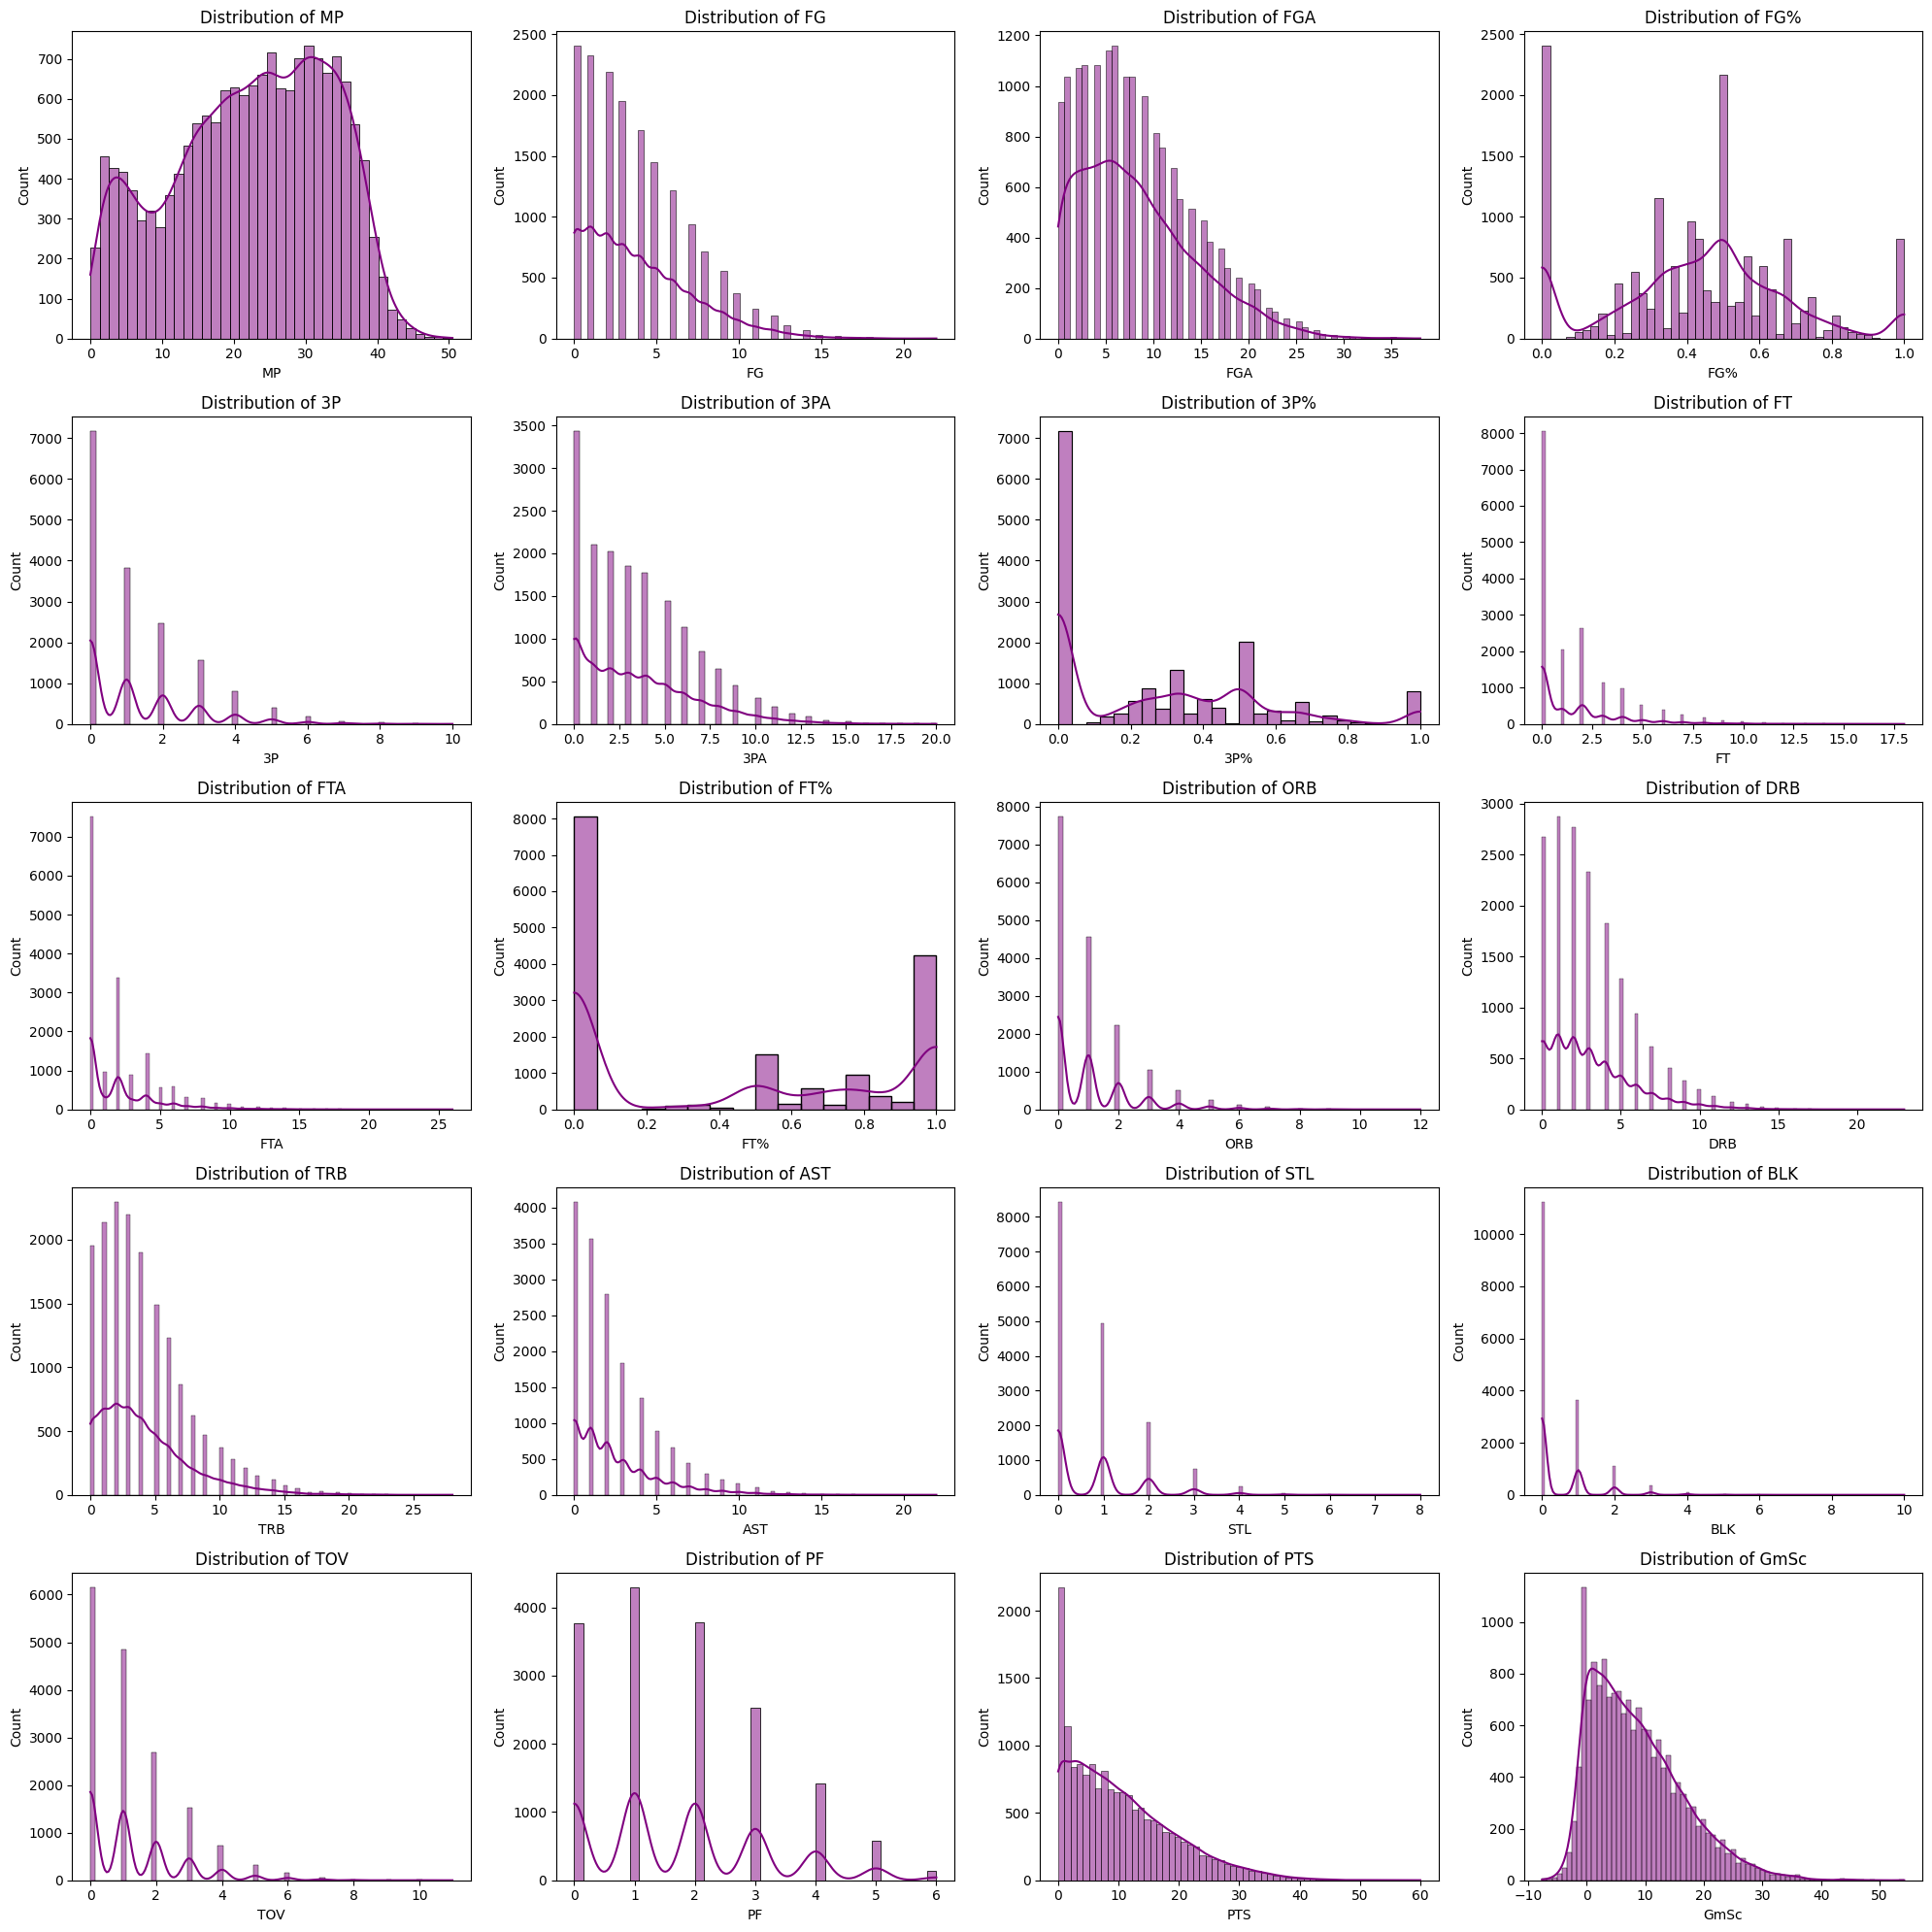

In [8]:
## Distribution Plots

fig, axes = plt.subplots(5, 4, figsize=(20, 20))
axes = axes.flatten()

for idx, feature in enumerate(numerical_features):
    sns.histplot(data[feature], kde=True, ax=axes[idx], color='purple')
    axes[idx].set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()


#### Insights 3:
- Most of The Data are Right skewed meaning that there are some outliers, (Best players stats are far from the average players')
- Good Labels could be PTS

#### Scater Plot Vs PTS

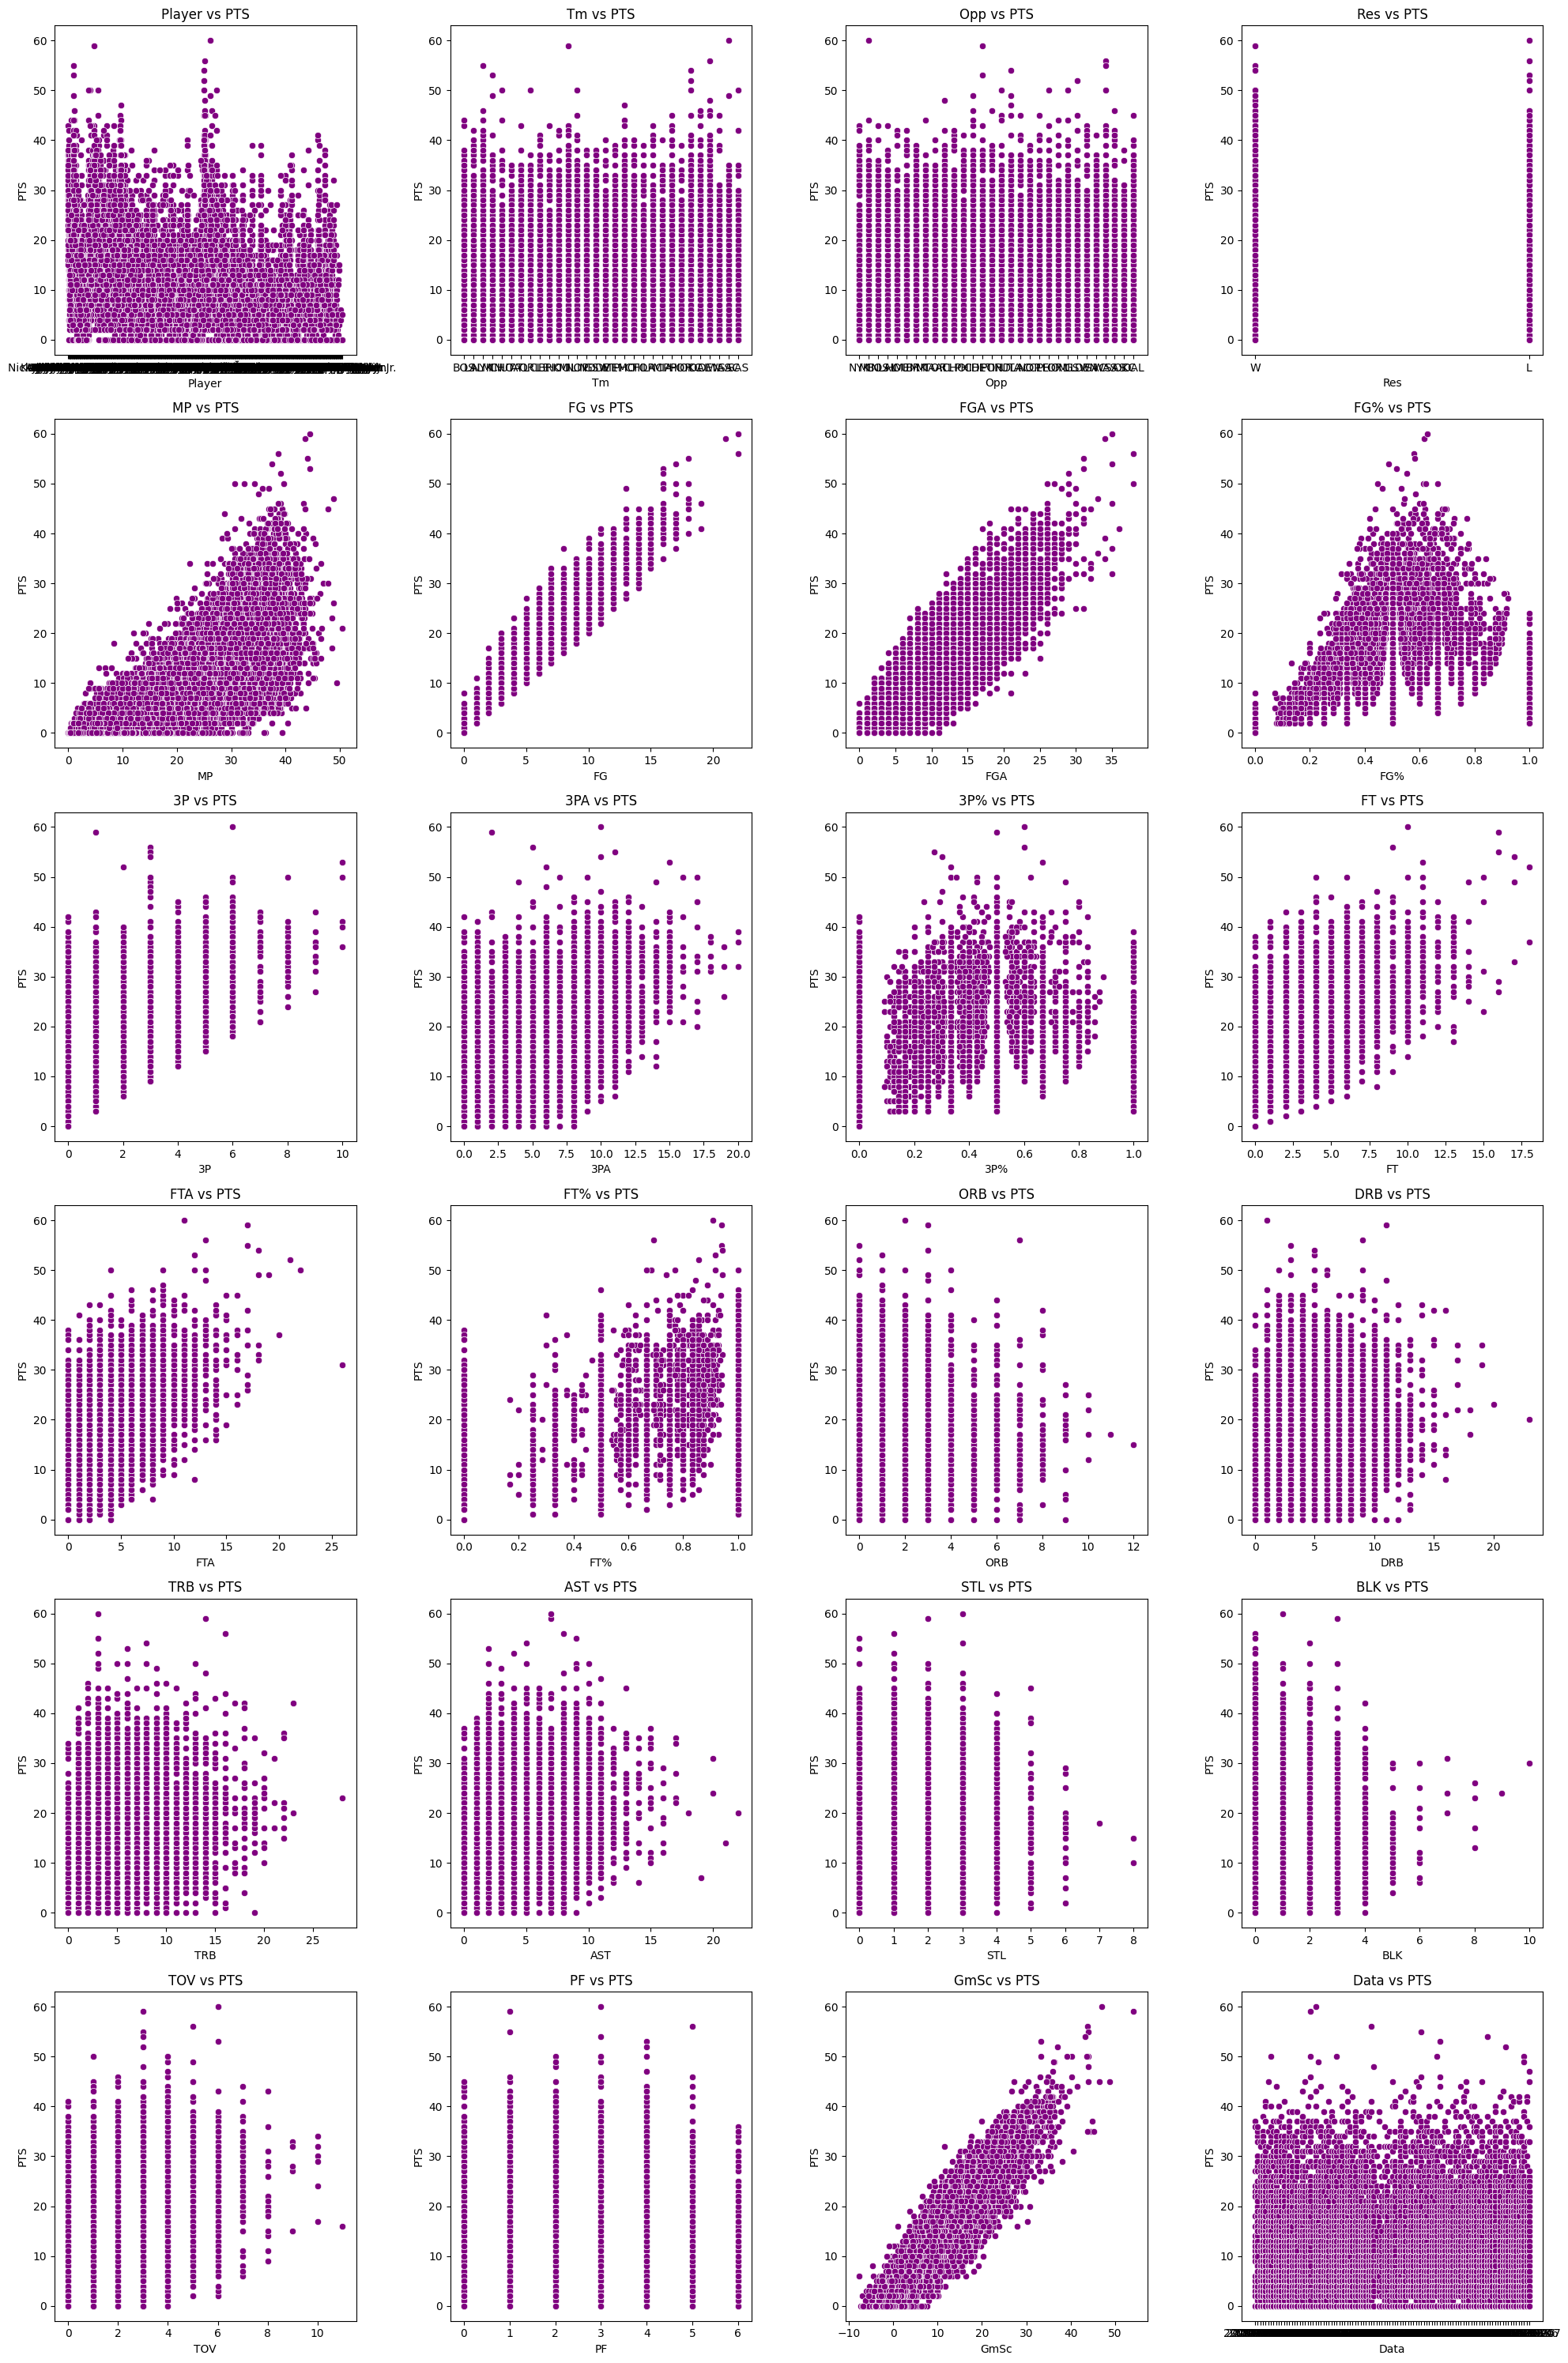

In [9]:
# Scatter Plots for Selected Features vs PTS

features_to_plot = data.columns
features_to_plot = features_to_plot.drop(['PTS']) 
num = len(features_to_plot)
n_cols = 4
n_rows = math.ceil(num / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

for idx, feature in enumerate(features_to_plot):
    sns.scatterplot(x=data[feature], y=data['PTS'], ax=axes[idx], color='purple')
    axes[idx].set_title(f"{feature} vs PTS")

plt.tight_layout()
plt.show()

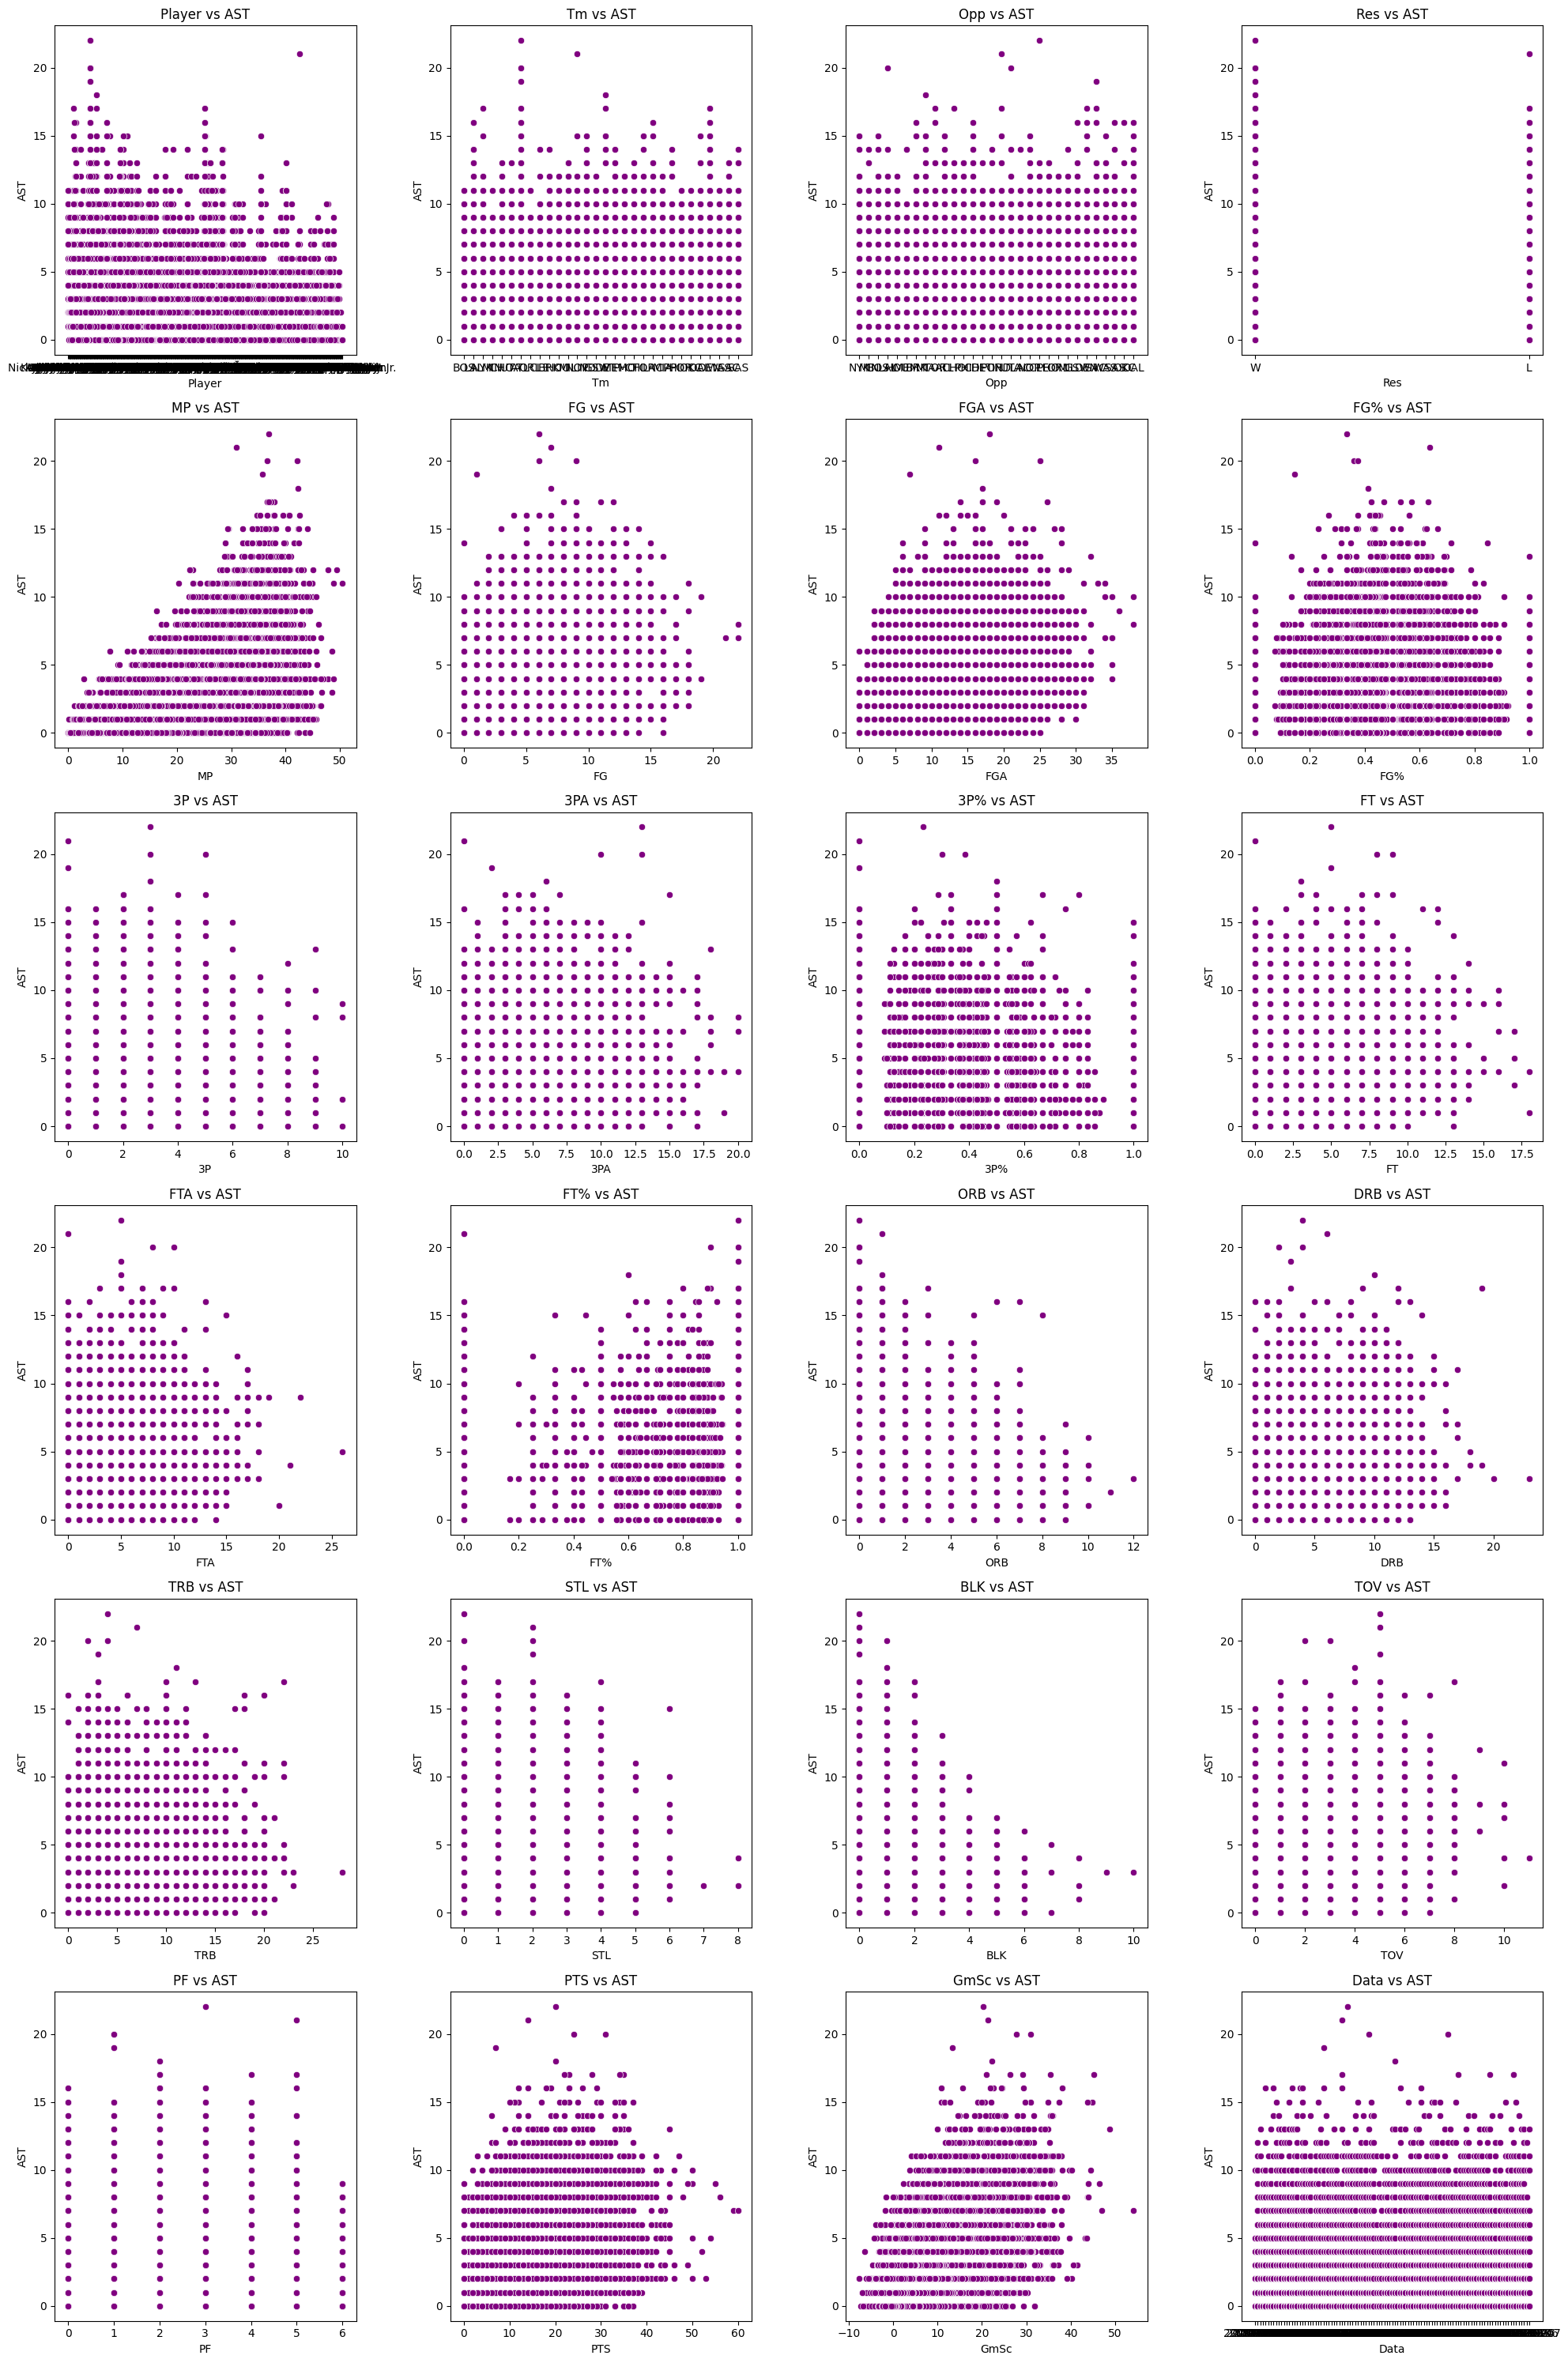

In [10]:
features_to_plot = data.columns
features_to_plot = features_to_plot.drop(['AST']) 
num = len(features_to_plot)
n_cols = 4
n_rows = math.ceil(num / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

for idx, feature in enumerate(features_to_plot):
    sns.scatterplot(x=data[feature], y=data['AST'], ax=axes[idx], color='purple')
    axes[idx].set_title(f"{feature} vs AST")

plt.tight_layout()
plt.show()

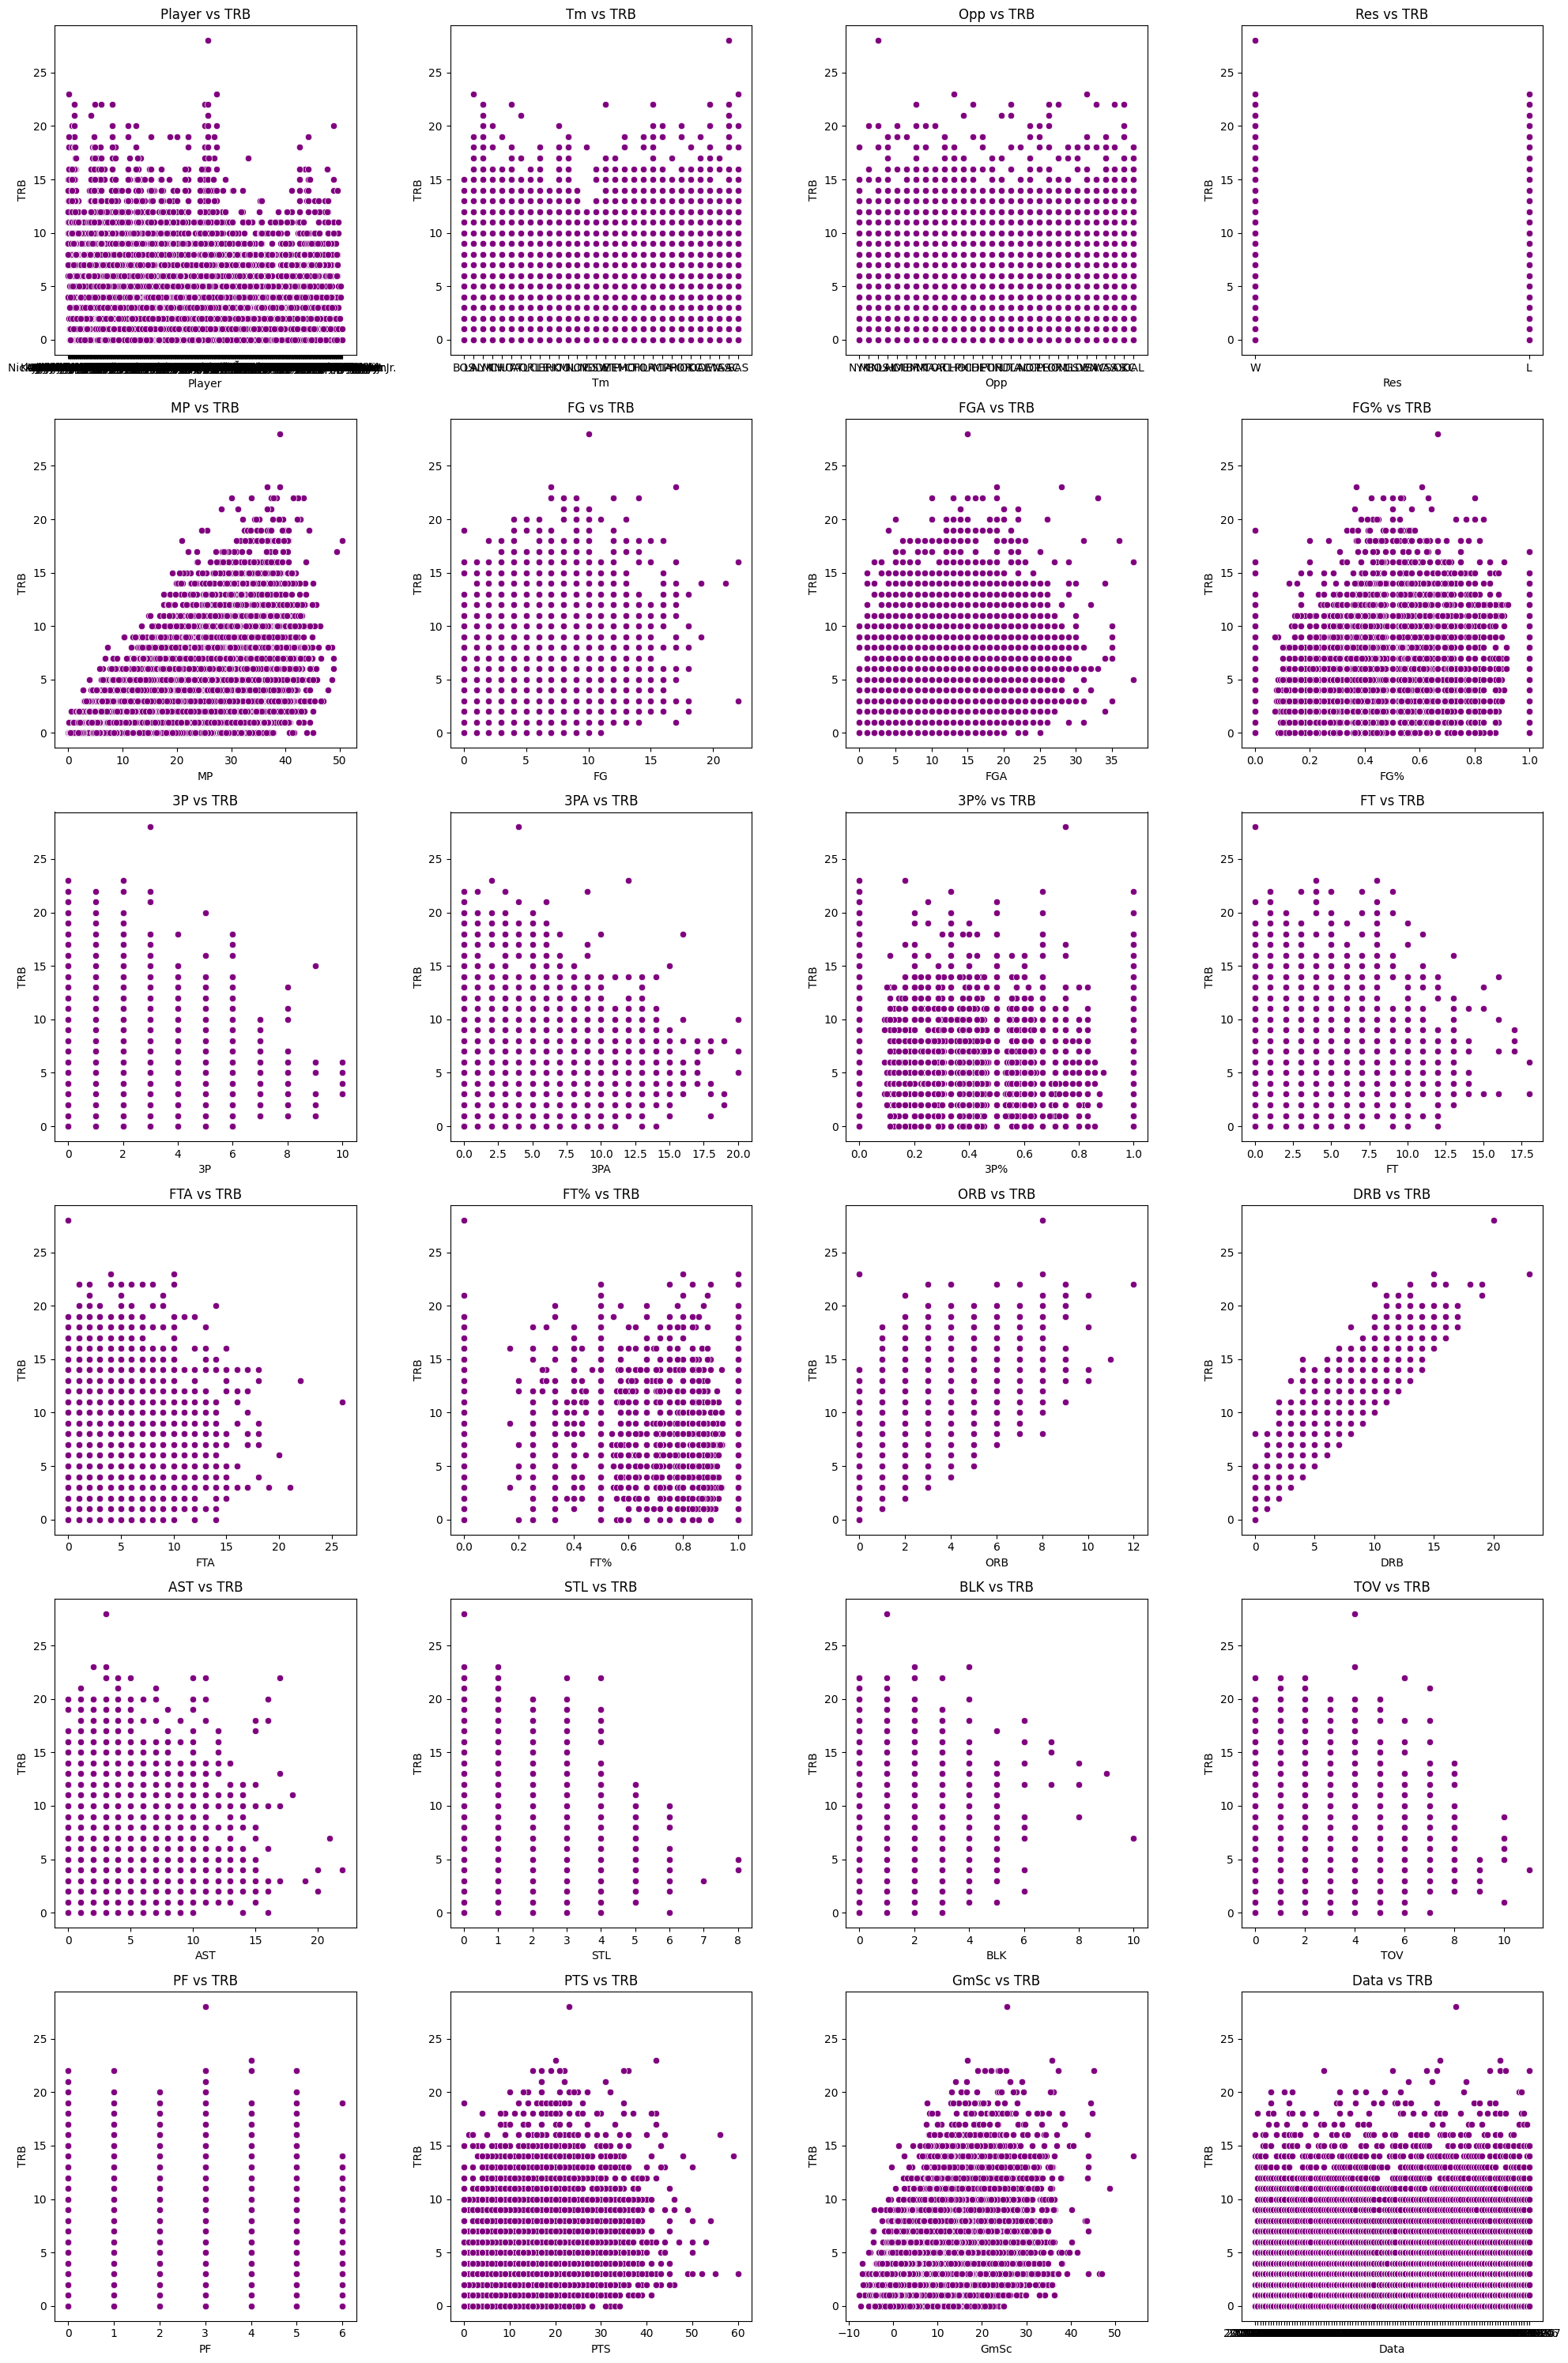

In [11]:
features_to_plot = data.columns
features_to_plot = features_to_plot.drop(['TRB']) 
num = len(features_to_plot)
n_cols = 4
n_rows = math.ceil(num / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

for idx, feature in enumerate(features_to_plot):
    sns.scatterplot(x=data[feature], y=data['TRB'], ax=axes[idx], color='purple')
    axes[idx].set_title(f"{feature} vs TRB")

plt.tight_layout()
plt.show()

#### Insights 4: Correlation against tagert labels

PTS showed that it is correlated with more features than the other two (TRB, AST), (So most probably PTS will be our Target value)

### Player Performnce

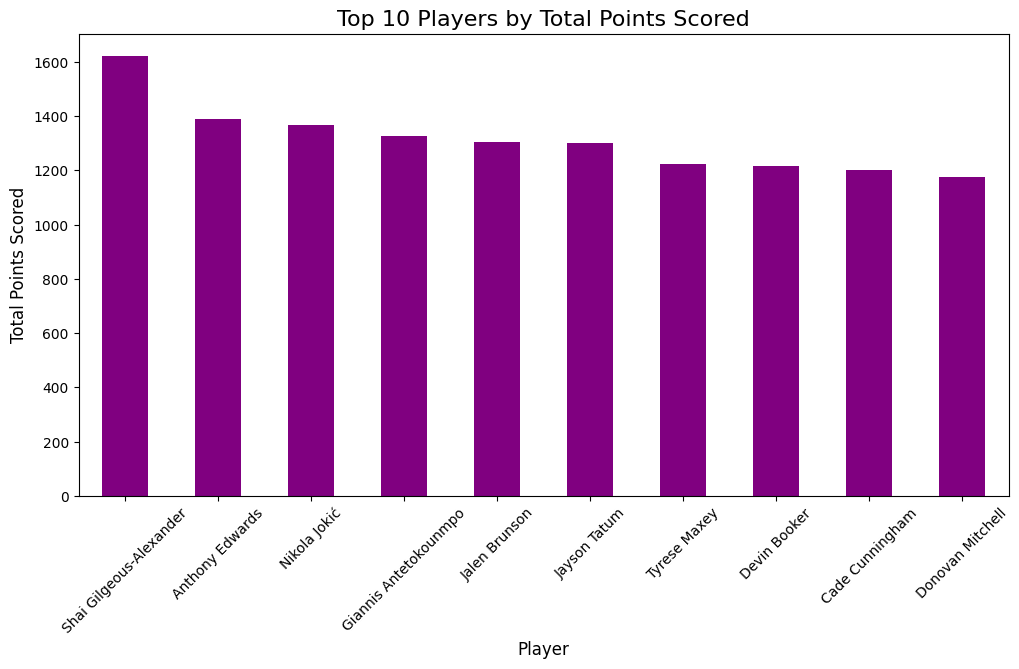

In [12]:
# Top 10 Players by Total Points Scored
top_scorers = data.groupby('Player')['PTS'].sum().sort_values(ascending=False).head(10)
top_scorers.plot(kind='bar', figsize=(12, 6), color='purple')
plt.title('Top 10 Players by Total Points Scored', fontsize=16)
plt.xlabel('Player', fontsize=12)
plt.ylabel('Total Points Scored', fontsize=12)
plt.xticks(rotation=45)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

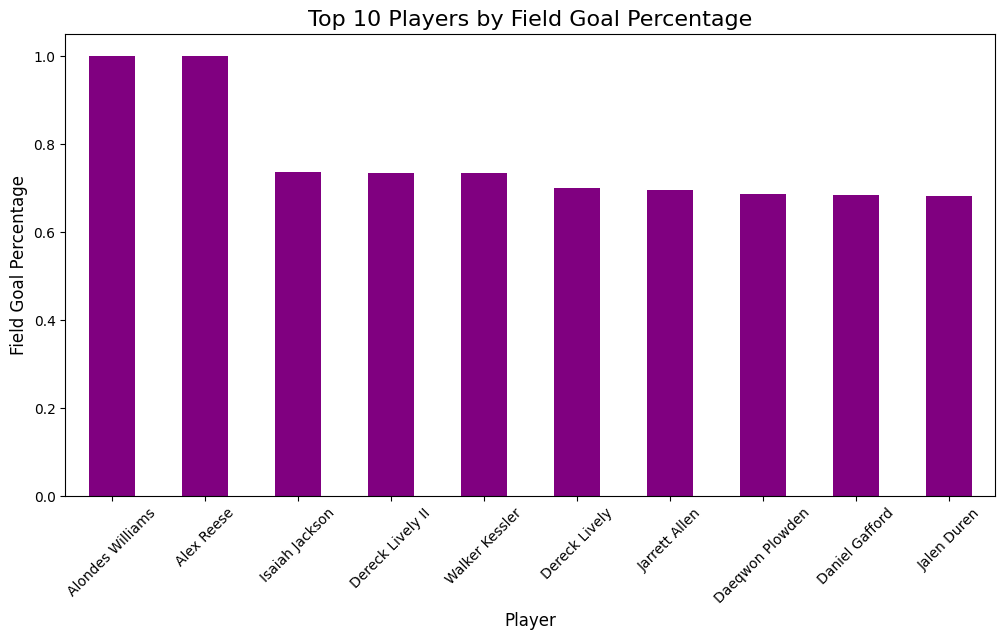

In [13]:
# Toop 10 players by Field Goal Percentage
top_fg_percentage = data.groupby('Player')['FG%'].mean().sort_values(ascending=False).head(10)
top_fg_percentage.plot(kind='bar', figsize=(12, 6), color='purple')
plt.title('Top 10 Players by Field Goal Percentage', fontsize=16)
plt.xlabel('Player', fontsize=12)
plt.ylabel('Field Goal Percentage', fontsize=12)
plt.xticks(rotation=45)
plt.show



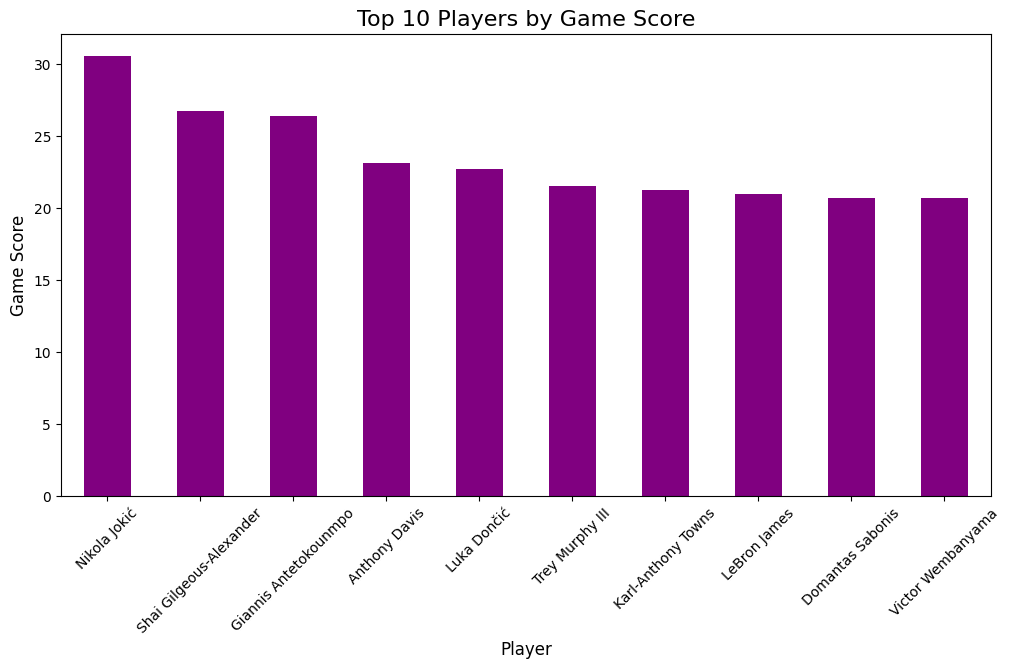

In [15]:
# Top 10 Players by Game Score
top_game_score = data.groupby('Player')['GmSc'].mean().sort_values(ascending=False).head(10)
top_game_score.plot(kind='bar', figsize=(12, 6), color='purple')
plt.title('Top 10 Players by Game Score', fontsize=16)
plt.xlabel('Player', fontsize=12)
plt.ylabel('Game Score', fontsize=12)
plt.xticks(rotation=45)
plt.show()



#### Insights 5: (Player performance) 

- Few players appear in both PTS and Game Score
- FG% Shows potential outliers or players who only had 1 shot 

### Class Imbalance

In [16]:
# Class Imbalance

win_counts = data['Res'].value_counts()
win_percentages = data['Res'].value_counts(normalize=True) * 100
#print(win_counts)

print("Absolute Counts:")
print(f"  Wins:     {win_counts[1]:,}")
print(f"  Loses: {win_counts[0]:,}")

print("\nPercentages:")
print(f"  Wins:     {win_percentages[1]:.1f}%")
print(f"  Loses: {win_percentages[0]:.1f}%")

# Calculate imbalance ratio
imbalance_ratio = win_counts.max() / win_counts.min()
print(f"\n⚖️ Imbalance Ratio: {imbalance_ratio:.1f}:1")

if imbalance_ratio > 1.5:
    print("🚨 IMBALANCED DATASET DETECTED!")
else:
    print("✅ Dataset appears balanced.")

Absolute Counts:
  Wins:     8,247
  Loses: 8,265

Percentages:
  Wins:     49.9%
  Loses: 50.1%

⚖️ Imbalance Ratio: 1.0:1
✅ Dataset appears balanced.


C:\Users\sonso\AppData\Local\Temp\ipykernel_14868\3945533954.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"  Wins:     {win_counts[1]:,}")
C:\Users\sonso\AppData\Local\Temp\ipykernel_14868\3945533954.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"  Loses: {win_counts[0]:,}")
C:\Users\sonso\AppData\Local\Temp\ipykernel_14868\3945533954.py:12: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"  Wins:    

## 2.0 Regression

### 2.1 Date Preprocessing

#### 2.1.1 Copy data, and drop MP = 0

In [4]:
reg_data = data[data['MP'] > 0].copy()

''' #We switched from timeseries to regular k fold split
reg_data['Data'] = pd.to_datetime(reg_data['Data'], format='%Y-%m-%d')
reg_data = reg_data.sort_values(by='Data', ascending=True)
reg_data = reg_data.reset_index(drop=True)

# Verify sorting and show information
print("="*70)
print("DATA PREPROCESSING SUMMARY")
print("="*70)
print(f"\nShape of the original data: {data.shape}")
print(f"Shape after MP > 0 filtering: {reg_data.shape}")
print(f"Rows removed (MP=0): {data.shape[0] - reg_data.shape[0]}")

print(f"\nDate range:")
print(f"  Earliest date: {reg_data['Data'].min()}")
print(f"  Latest date:   {reg_data['Data'].max()}")

print(f"\nFirst 5 dates (should be ascending):")
print(reg_data['Data'].head(50).tolist())

print(f"\nLast 5 dates (should be ascending):")
print(reg_data['Data'].tail(50).tolist())

is_sorted = reg_data['Data'].is_monotonic_increasing
print(f"\n✓ Dates are properly sorted: {is_sorted}")
print("="*70)'''


' #We switched from timeseries to regular k fold split\nreg_data[\'Data\'] = pd.to_datetime(reg_data[\'Data\'], format=\'%Y-%m-%d\')\nreg_data = reg_data.sort_values(by=\'Data\', ascending=True)\nreg_data = reg_data.reset_index(drop=True)\n\n# Verify sorting and show information\nprint("="*70)\nprint("DATA PREPROCESSING SUMMARY")\nprint("="*70)\nprint(f"\nShape of the original data: {data.shape}")\nprint(f"Shape after MP > 0 filtering: {reg_data.shape}")\nprint(f"Rows removed (MP=0): {data.shape[0] - reg_data.shape[0]}")\n\nprint(f"\nDate range:")\nprint(f"  Earliest date: {reg_data[\'Data\'].min()}")\nprint(f"  Latest date:   {reg_data[\'Data\'].max()}")\n\nprint(f"\nFirst 5 dates (should be ascending):")\nprint(reg_data[\'Data\'].head(50).tolist())\n\nprint(f"\nLast 5 dates (should be ascending):")\nprint(reg_data[\'Data\'].tail(50).tolist())\n\nis_sorted = reg_data[\'Data\'].is_monotonic_increasing\nprint(f"\n✓ Dates are properly sorted: {is_sorted}")\nprint("="*70)'

#### 2.1.2 Feature Engineering

In [5]:
# True Shooting Percentage (TS%)
reg_data['TS%'] = reg_data['PTS'] / (2 * (reg_data['FGA'] + 0.44 * reg_data['FTA']))
print("Null values in TS% after calculation:", reg_data['TS%'].isnull().sum())
reg_data['TS%'] = reg_data['TS%'].fillna(0.0)
print("Null values in TS% after filling:", reg_data['TS%'].isnull().sum())


Null values in TS% after calculation: 828
Null values in TS% after filling: 0


In [6]:
# Assits to Turnover Ratio (AST/TO)
epsilon = 1e-10
reg_data['AST/TO'] = reg_data['AST'] / (reg_data['TOV'] + epsilon)
print("Null values in AST/TO after calculation:", reg_data['AST/TO'].isnull().sum())


Null values in AST/TO after calculation: 0


In [8]:
# Defensive Impact
reg_data['Def_Impact'] = (reg_data['STL'] + reg_data['BLK'] + reg_data['DRB']) / reg_data['MP']
print("Null values in Def_Impact after calculation:", reg_data['Def_Impact'].isnull().sum())

Null values in Def_Impact after calculation: 0


In [9]:
# offensive Impact
reg_data['Off_Impact'] = (reg_data['AST'] + reg_data['ORB']) / reg_data['MP']
print("Null values in Off_Impact after calculation:", reg_data['Off_Impact'].isnull().sum())

Null values in Off_Impact after calculation: 0


In [10]:
# three point attempt rate
reg_data['3P_Arate'] = reg_data['3PA'] / (reg_data['FGA'] + epsilon)
print("Null values in 3P_Arate after calculation:", reg_data['3P_Arate'].isnull().sum())

Null values in 3P_Arate after calculation: 0


In [11]:
#free throw attempt rate
reg_data['FT_Arate'] = reg_data['FTA'] / (reg_data['FGA'] + epsilon)
print("Null values in FT_Arate after calculation:", reg_data['FT_Arate'].isnull().sum())

Null values in FT_Arate after calculation: 0


In [12]:
# Shooting frequency
reg_data['Shooting_Freq'] = reg_data['FGA'] / reg_data['MP']
print("Null values in Shooting_Freq after calculation:", reg_data['Shooting_Freq'].isnull().sum())

Null values in Shooting_Freq after calculation: 0


In [13]:
#volume x playing time
reg_data['Volume_Playtime'] = reg_data['FGA'] * reg_data['MP']
print("Null values in Volume_Playtime after calculation:", reg_data['Volume_Playtime'].isnull().sum())

Null values in Volume_Playtime after calculation: 0


### 2.2 Splitting Data

In [14]:
features_to_drop = ["Player", "Data", "Res", "FG", "3P", "FT", "GmSc", "FG%", "3P%", "FT%", "TS%"]
target = 'PTS'
categorical_features = ['Tm', 'Opp']

# Approach 1 Drop categorical features
reg_data_model_1 = reg_data.drop(columns=features_to_drop+categorical_features)
x_no_cat = reg_data_model_1.drop(columns=[target])
y_no_cat = reg_data_model_1[target]


print("Model 1 (No Categorical) X Shape:", x_no_cat.shape)
print("Model 1 (No Categorical) Y Shape:", y_no_cat.shape)

# Approach 2 One-Hot Encoding for categorical features
reg_data_model_2 = reg_data.drop(columns=features_to_drop)
reg_data_model_2 = pd.get_dummies(reg_data_model_2, columns=categorical_features, drop_first=True)
x_with_cat = reg_data_model_2.drop(columns=[target])
y_with_cat = reg_data_model_2[target]
print("Model 2 (With Categorical) X Shape:", x_with_cat.shape)
print("Model 2 (With Categorical) Y Shape:", y_with_cat.shape)


Model 1 (No Categorical) X Shape: (16508, 19)
Model 1 (No Categorical) Y Shape: (16508,)
Model 2 (With Categorical) X Shape: (16508, 77)
Model 2 (With Categorical) Y Shape: (16508,)


### 2.3 Training

#### 2.3.1 Training No categorical Features 

In [27]:
x_no_cat.columns.tolist()

['MP',
 'FGA',
 '3PA',
 'FTA',
 'ORB',
 'DRB',
 'TRB',
 'AST',
 'STL',
 'BLK',
 'TOV',
 'PF',
 'AST/TO',
 'Def_Impact',
 'Off_Impact',
 '3P_Arate',
 'FT_Arate',
 'Shooting_Freq',
 'Volume_Playtime']

In [15]:
X = x_no_cat
y = y_no_cat

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'R2': 'r2', 'MSE': 'neg_mean_squared_error'}

pipelines = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr_model', LinearRegression())
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('rf_model', RandomForestRegressor(n_estimators=60, random_state=42, max_depth=5, min_samples_leaf=4, n_jobs=-1))
    ]),
    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('mlp_model', MLPRegressor(hidden_layer_sizes=(100),activation='relu', max_iter=500, 
                                   random_state=42, early_stopping=True, alpha=0.001, solver='adam' ))
    ])   
}

#results
results = {}
for model_name, pipeline in pipelines.items():
    cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=True)
    train_mse = -cv_results['train_MSE']
    train_r2 = cv_results['train_R2']
    test_mse = -cv_results['test_MSE']
    test_r2 = cv_results['test_R2']
    results[model_name] = {
        'train_mse_mean': np.mean(train_mse),
        'train_r2_mean': np.mean(train_r2),
        'test_mse_mean': np.mean(test_mse),
        'test_r2_mean': np.mean(test_r2),
        'train_mse_folds': train_mse,
        'test_mse_folds': test_mse,
        'estimators': cv_results['estimator']
    }
    
    # Store MLP loss curves (epochs) for  NN
    if model_name == 'Neural Network':
        mlp_loss_curves = []
        for estimator in cv_results['estimator']:
            mlp_model = estimator.named_steps['mlp_model']
            mlp_loss_curves.append(mlp_model.loss_curve_)
        results[model_name]['mlp_loss_curves'] = mlp_loss_curves

# Print scores for all models first
print("="*70)
print("MODEL PERFORMANCE SUMMARY")
print("="*70)
for model_name in results.keys():
    train_mse = results[model_name]['train_mse_folds']
    train_r2 = results[model_name]['train_r2_mean']
    test_mse_mean = results[model_name]['test_mse_mean']
    test_r2_mean = results[model_name]['test_r2_mean']
    
    print(f"\nModel: {model_name}")
    print(f"MSE per fold (train): {train_mse}")
    print(f"Train MSE: {np.mean(train_mse):.2f}, Train R2: {train_r2:.4f}")
    print(f"Test MSE:  {test_mse_mean:.2f}, Test R2:  {test_r2_mean:.4f}")

# Print feature importances (averaged across folds) for all models
print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)
for model_name in results.keys():
    estimators = results[model_name]['estimators']
    
    # Collect feature importances from all folds
    all_importances = []
    for estimator in estimators:
        if model_name == 'Random Forest':
            feature_importances = estimator.named_steps['rf_model'].feature_importances_
        elif model_name == 'Linear Regression':
            feature_importances = np.abs(estimator.named_steps['lr_model'].coef_)
        elif model_name == 'Neural Network':
            feature_importances = np.abs(estimator.named_steps['mlp_model'].coefs_[0]).mean(axis=1)
        all_importances.append(feature_importances)
    
    # Average feature importances across all folds
    avg_importances = np.mean(all_importances, axis=0)
    
    feature_importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': avg_importances
    }).sort_values(by='Importance', ascending=False)
    
    print(f"\n{model_name} - Top 10 Feature Importances (averaged across folds):")
    print(feature_importance_df.head(10))



MODEL PERFORMANCE SUMMARY

Model: Linear Regression
MSE per fold (train): [11.86311986 11.90844988 11.96409916 11.97136672 11.83728299]
Train MSE: 11.91, Train R2: 0.8472
Test MSE:  11.95, Test R2:  0.8466

Model: Random Forest
MSE per fold (train): [11.98126515 12.02021947 12.13654259 12.04718365 11.93726988]
Train MSE: 12.02, Train R2: 0.8457
Test MSE:  12.48, Test R2:  0.8397

Model: Neural Network
MSE per fold (train): [11.5263604  11.56810737 11.63997355 11.52525923 11.42650828]
Train MSE: 11.54, Train R2: 0.8520
Test MSE:  11.99, Test R2:  0.8460

FEATURE IMPORTANCE ANALYSIS

Linear Regression - Top 10 Feature Importances (averaged across folds):
            Feature  Importance
1               FGA    5.629676
3               FTA    2.174738
18  Volume_Playtime    0.562052
2               3PA    0.557298
0                MP    0.273900
15         3P_Arate    0.236403
7               AST    0.157642
5               DRB    0.149998
4               ORB    0.142933
6               TRB

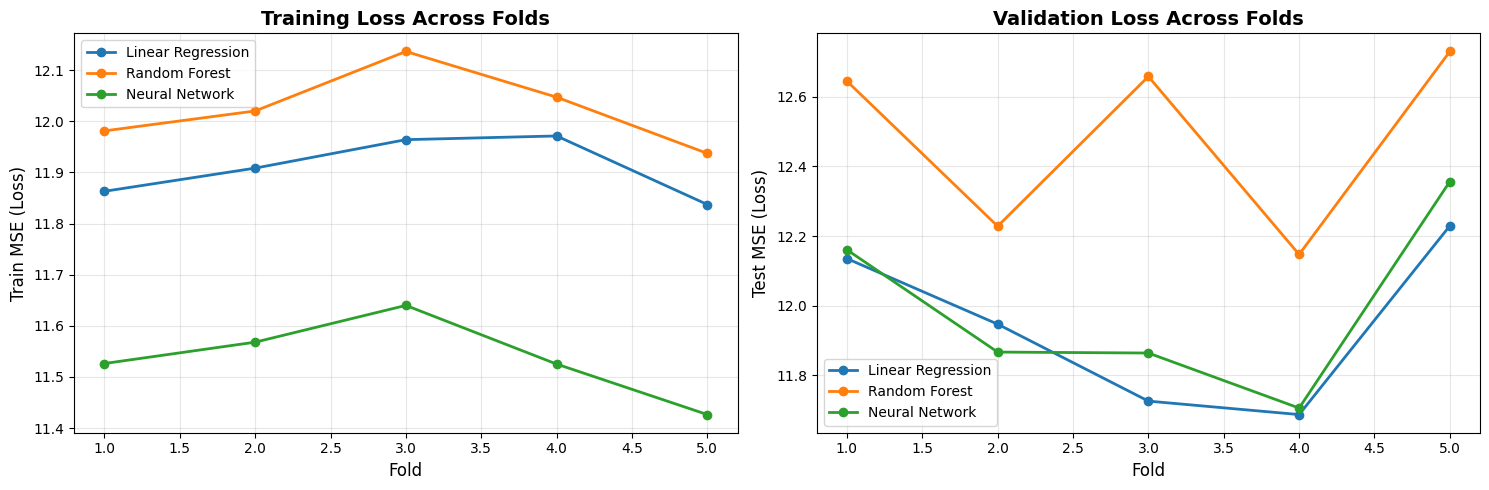

In [16]:
# Plot Loss Curves (MSE across folds)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Train MSE across folds
for model_name in results.keys():
    folds = np.arange(1, 6)
    axes[0].plot(folds, results[model_name]['train_mse_folds'], marker='o', label=model_name, linewidth=2)

axes[0].set_xlabel('Fold', fontsize=12)
axes[0].set_ylabel('Train MSE (Loss)', fontsize=12)
axes[0].set_title('Training Loss Across Folds', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Test MSE across folds
for model_name in results.keys():
    folds = np.arange(1, 6)
    axes[1].plot(folds, results[model_name]['test_mse_folds'], marker='o', label=model_name, linewidth=2)

axes[1].set_xlabel('Fold', fontsize=12)
axes[1].set_ylabel('Test MSE (Loss)', fontsize=12)
axes[1].set_title('Validation Loss Across Folds', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

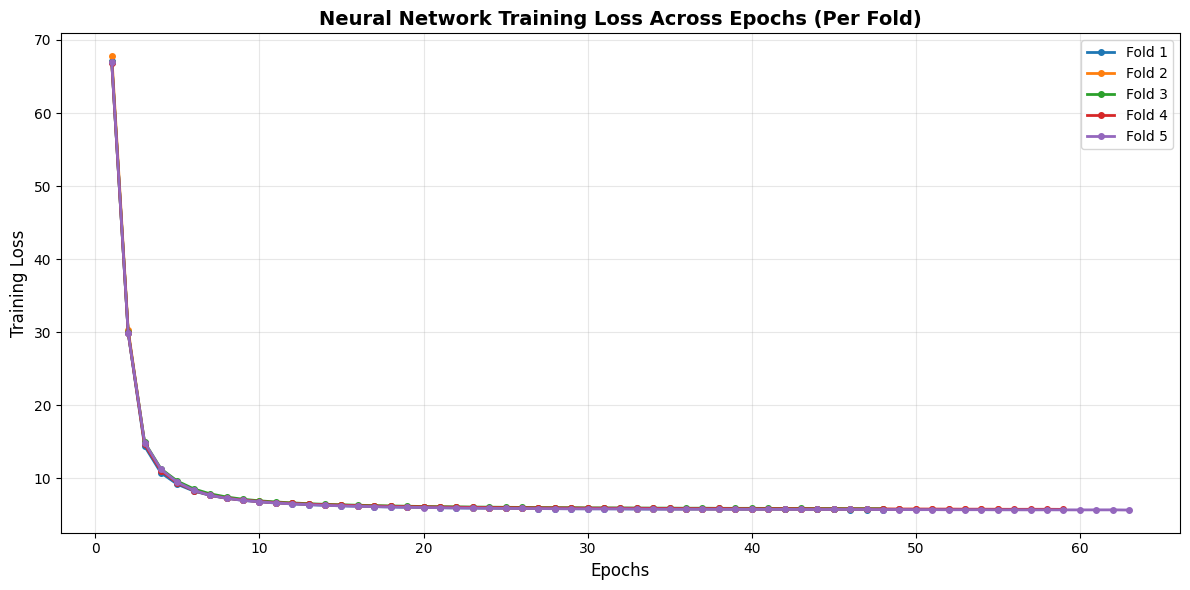


MLP Convergence Information:
Fold 1: Converged in 49 epochs, Final Loss: 5.7248
Fold 2: Converged in 55 epochs, Final Loss: 5.7488
Fold 3: Converged in 48 epochs, Final Loss: 5.8379
Fold 4: Converged in 59 epochs, Final Loss: 5.7399
Fold 5: Converged in 63 epochs, Final Loss: 5.6515


In [17]:
# Plot MLP Loss Curves (Training Loss vs Epochs)
if 'Neural Network' in results and 'mlp_loss_curves' in results['Neural Network']:
    mlp_curves = results['Neural Network']['mlp_loss_curves']
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    for fold_idx, loss_curve in enumerate(mlp_curves):
        epochs = np.arange(1, len(loss_curve) + 1)
        ax.plot(epochs, loss_curve, marker='o', label=f'Fold {fold_idx + 1}', linewidth=2, markersize=4)
    
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Training Loss', fontsize=12)
    ax.set_title('Neural Network Training Loss Across Epochs (Per Fold)', fontsize=14, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Print convergence info
    print("\nMLP Convergence Information:")
    for fold_idx, loss_curve in enumerate(mlp_curves):
        print(f"Fold {fold_idx + 1}: Converged in {len(loss_curve)} epochs, Final Loss: {loss_curve[-1]:.4f}")
else:
    print("No MLP loss curves available. Please run the training cell first.")

In [18]:
# Manual for loop, not using pipelines


X = x_no_cat
y = y_no_cat

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results= {'LinearRegression': [], 'RandomForest': [], 'NeuralNetwork': []}
for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Linear Regression
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    lr_model = LinearRegression()
    lr_model.fit(X_train_scaled, y_train)
    y_pred_lr = lr_model.predict(X_test_scaled)
    results['LinearRegression'].append({
        'Train MSE': mean_squared_error(y_train, lr_model.predict(X_train_scaled)),
        'Train R2': r2_score(y_train, lr_model.predict(X_train_scaled)),
        'Test MSE': mean_squared_error(y_test, y_pred_lr),
        'Test R2': r2_score(y_test, y_pred_lr)
    })
    # Random Forest
    rf_model = RandomForestRegressor(n_estimators=60, random_state=42, max_depth=5, min_samples_leaf=4, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)
    results['RandomForest'].append({
        'Train MSE': mean_squared_error(y_train, rf_model.predict(X_train)),
        'Train R2': r2_score(y_train, rf_model.predict(X_train)),
        'Test MSE': mean_squared_error(y_test, y_pred_rf),
        'Test R2': r2_score(y_test, y_pred_rf)
    })
    # Neural Network
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    nn_model = MLPRegressor(hidden_layer_sizes=(100), activation='relu', max_iter=500, random_state=42, early_stopping=True, alpha=0.001, solver='adam')
    nn_model.fit(X_train_scaled, y_train)
    y_pred_nn = nn_model.predict(X_test_scaled)
    results['NeuralNetwork'].append({
        'Train MSE': mean_squared_error(y_train, nn_model.predict(X_train_scaled)),
        'Train R2': r2_score(y_train, nn_model.predict(X_train_scaled)),
        'Test MSE': mean_squared_error(y_test, y_pred_nn),
        'Test R2': r2_score(y_test, y_pred_nn)
    })
for model_name, metrics in results.items():
    train_mse = np.mean([m['Train MSE'] for m in metrics])
    train_r2 = np.mean([m['Train R2'] for m in metrics])
    test_mse = np.mean([m['Test MSE'] for m in metrics])
    test_r2 = np.mean([m['Test R2'] for m in metrics])
    print(f"\nModel: {model_name}")
    print(f"Train MSE: {train_mse:.2f}, Train R2: {train_r2:.4f}")
    print(f"Test MSE: {test_mse:.2f}, Test R2: {test_r2:.4f}")
    




Model: LinearRegression
Train MSE: 11.91, Train R2: 0.8472
Test MSE: 11.95, Test R2: 0.8466

Model: RandomForest
Train MSE: 12.02, Train R2: 0.8458
Test MSE: 12.49, Test R2: 0.8396

Model: NeuralNetwork
Train MSE: 11.54, Train R2: 0.8520
Test MSE: 11.99, Test R2: 0.8460


#### 2.3.2 Training With categorical Features 

In [19]:
X = x_with_cat
y = y_with_cat

cv = KFold(n_splits=5, shuffle=True, random_state=42)


scoring = {'R2': 'r2', 'MSE': 'neg_mean_squared_error'}

pipelines = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr_model', LinearRegression())
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('rf_model', RandomForestRegressor(n_estimators=60, random_state=42, max_depth=5, min_samples_leaf=4, n_jobs=-1))
    ]),
    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('mlp_model', MLPRegressor(hidden_layer_sizes=(100),activation='relu', max_iter=500, 
                                   random_state=42, early_stopping=True, alpha=0.001, solver='adam' ))
    ])   
}

results = {}
for model_name, pipeline in pipelines.items():
    cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=True)
    train_mse = -cv_results['train_MSE']
    train_r2 = cv_results['train_R2']
    test_mse = -cv_results['test_MSE']
    test_r2 = cv_results['test_R2']
    results[model_name] = {
        'train_mse_mean': np.mean(train_mse),
        'train_r2_mean': np.mean(train_r2),
        'test_mse_mean': np.mean(test_mse),
        'test_r2_mean': np.mean(test_r2),
        'train_mse_folds': train_mse,
        'test_mse_folds': test_mse,
        'estimators': cv_results['estimator']
    }
    
    # Store MLP loss curves (epochs)
    if model_name == 'Neural Network':
        mlp_loss_curves = []
        for estimator in cv_results['estimator']:
            mlp_model = estimator.named_steps['mlp_model']
            mlp_loss_curves.append(mlp_model.loss_curve_)
        results[model_name]['mlp_loss_curves'] = mlp_loss_curves

# Print scores for all models first
print("="*70)
print("MODEL PERFORMANCE SUMMARY")
print("="*70)
for model_name in results.keys():
    train_mse = results[model_name]['train_mse_folds']
    train_r2 = results[model_name]['train_r2_mean']
    test_mse_mean = results[model_name]['test_mse_mean']
    test_r2_mean = results[model_name]['test_r2_mean']
    
    print(f"\nModel: {model_name}")
    print(f"MSE per fold (train): {train_mse}")
    print(f"Train MSE: {np.mean(train_mse):.2f}, Train R2: {train_r2:.4f}")
    print(f"Test MSE:  {test_mse_mean:.2f}, Test R2:  {test_r2_mean:.4f}")

# Print feature importances (averaged across folds) for all models
print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)
for model_name in results.keys():
    estimators = results[model_name]['estimators']
    
    # Collect feature importances from all folds
    all_importances = []
    for estimator in estimators:
        if model_name == 'Random Forest':
            feature_importances = estimator.named_steps['rf_model'].feature_importances_
        elif model_name == 'Linear Regression':
            feature_importances = np.abs(estimator.named_steps['lr_model'].coef_)
        elif model_name == 'Neural Network':
            feature_importances = np.abs(estimator.named_steps['mlp_model'].coefs_[0]).mean(axis=1)
        all_importances.append(feature_importances)
    
    # Average feature importances across all folds
    avg_importances = np.mean(all_importances, axis=0)
    
    feature_importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': avg_importances
    }).sort_values(by='Importance', ascending=False)
    
    print(f"\n{model_name} - Top 10 Feature Importances (averaged across folds):")
    print(feature_importance_df.head(10))



MODEL PERFORMANCE SUMMARY

Model: Linear Regression
MSE per fold (train): [11.67625013 11.73538727 11.77720323 11.78751435 11.66045994]
Train MSE: 11.73, Train R2: 0.8495
Test MSE:  11.85, Test R2:  0.8477

Model: Random Forest
MSE per fold (train): [11.97944428 12.02030704 12.13408894 12.04348813 11.93790317]
Train MSE: 12.02, Train R2: 0.8457
Test MSE:  12.49, Test R2:  0.8397

Model: Neural Network
MSE per fold (train): [10.50279661 10.33044165 10.9072254  10.73337888 10.41415148]
Train MSE: 10.58, Train R2: 0.8643
Test MSE:  12.43, Test R2:  0.8403

FEATURE IMPORTANCE ANALYSIS

Linear Regression - Top 10 Feature Importances (averaged across folds):
            Feature  Importance
1               FGA    5.624303
3               FTA    2.181188
2               3PA    0.577592
18  Volume_Playtime    0.525980
0                MP    0.316895
15         3P_Arate    0.251726
7               AST    0.203798
23           Tm_CLE    0.180490
67          Opp_OKC    0.152297
5               DRB

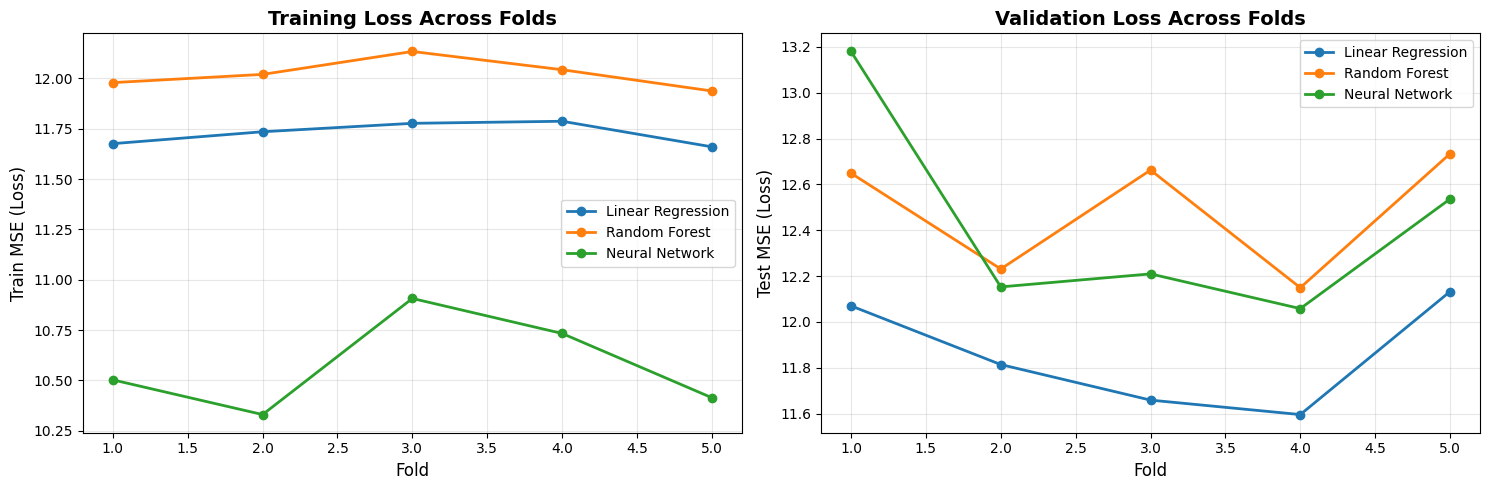

In [20]:
# Plot Loss Curves (MSE across folds)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Train MSE across folds
for model_name in results.keys():
    folds = np.arange(1, 6)
    axes[0].plot(folds, results[model_name]['train_mse_folds'], marker='o', label=model_name, linewidth=2)

axes[0].set_xlabel('Fold', fontsize=12)
axes[0].set_ylabel('Train MSE (Loss)', fontsize=12)
axes[0].set_title('Training Loss Across Folds', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Test MSE across folds
for model_name in results.keys():
    folds = np.arange(1, 6)
    axes[1].plot(folds, results[model_name]['test_mse_folds'], marker='o', label=model_name, linewidth=2)

axes[1].set_xlabel('Fold', fontsize=12)
axes[1].set_ylabel('Test MSE (Loss)', fontsize=12)
axes[1].set_title('Validation Loss Across Folds', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

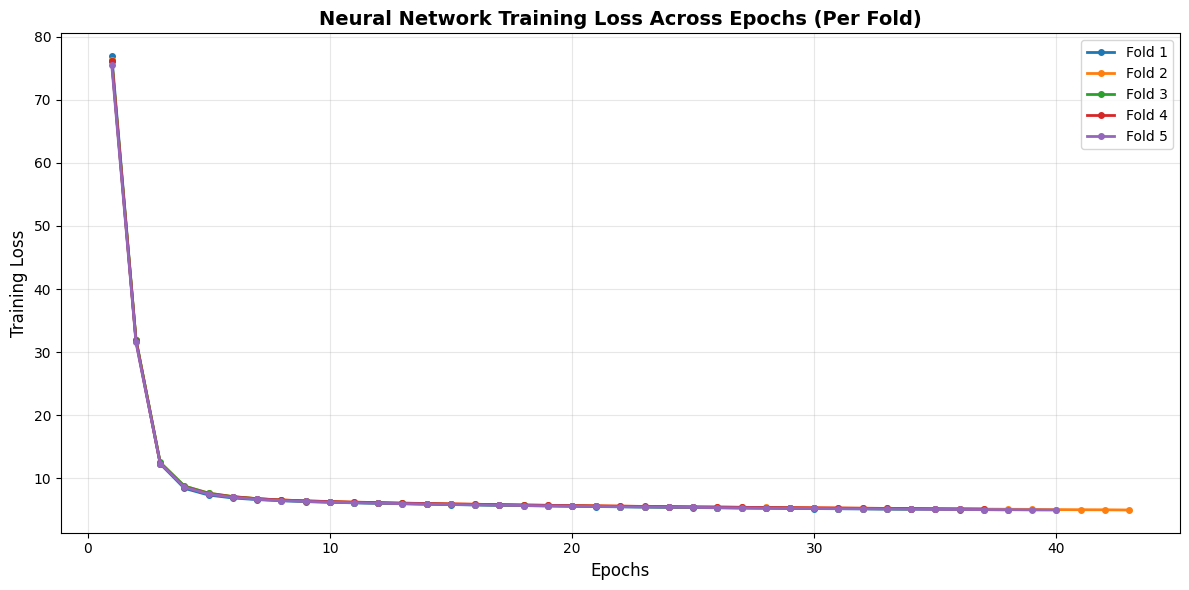


MLP Convergence Information:
Fold 1: Converged in 38 epochs, Final Loss: 4.9618
Fold 2: Converged in 43 epochs, Final Loss: 4.9346
Fold 3: Converged in 34 epochs, Final Loss: 5.0897
Fold 4: Converged in 37 epochs, Final Loss: 5.0969
Fold 5: Converged in 40 epochs, Final Loss: 4.9322


In [21]:
# Plot MLP Loss Curves (Training Loss vs Epochs)
if 'Neural Network' in results and 'mlp_loss_curves' in results['Neural Network']:
    mlp_curves = results['Neural Network']['mlp_loss_curves']
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    for fold_idx, loss_curve in enumerate(mlp_curves):
        epochs = np.arange(1, len(loss_curve) + 1)
        ax.plot(epochs, loss_curve, marker='o', label=f'Fold {fold_idx + 1}', linewidth=2, markersize=4)
    
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Training Loss', fontsize=12)
    ax.set_title('Neural Network Training Loss Across Epochs (Per Fold)', fontsize=14, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Print convergence info
    print("\nMLP Convergence Information:")
    for fold_idx, loss_curve in enumerate(mlp_curves):
        print(f"Fold {fold_idx + 1}: Converged in {len(loss_curve)} epochs, Final Loss: {loss_curve[-1]:.4f}")
else:
    print("No MLP loss curves available. Please run the training cell first.")

In [23]:
X = x_with_cat
y = y_with_cat

kf = KFold(n_splits=5, shuffle=True, random_state=42)


results= {'LinearRegression': [], 'RandomForest': [], 'NeuralNetwork': []}
for train_index, test_index in kf.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Linear Regression
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    lr_model = LinearRegression()
    lr_model.fit(X_train_scaled, y_train)
    y_pred_lr = lr_model.predict(X_test_scaled)
    results['LinearRegression'].append({
        'Train MSE': mean_squared_error(y_train, lr_model.predict(X_train_scaled)),
        'Train R2': r2_score(y_train, lr_model.predict(X_train_scaled)),
        'Test MSE': mean_squared_error(y_test, y_pred_lr),
        'Test R2': r2_score(y_test, y_pred_lr)
    })
    # Random Forest
    rf_model = RandomForestRegressor(n_estimators=60, random_state=42, max_depth=5, min_samples_leaf=4, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)
    results['RandomForest'].append({
        'Train MSE': mean_squared_error(y_train, rf_model.predict(X_train)),
        'Train R2': r2_score(y_train, rf_model.predict(X_train)),
        'Test MSE': mean_squared_error(y_test, y_pred_rf),
        'Test R2': r2_score(y_test, y_pred_rf)
    })
    # Neural Network
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    nn_model = MLPRegressor(hidden_layer_sizes=(100), activation='relu', max_iter=500, random_state=42, early_stopping=True, alpha=0.001, solver='adam')
    nn_model.fit(X_train_scaled, y_train)
    y_pred_nn = nn_model.predict(X_test_scaled)
    results['NeuralNetwork'].append({
        'Train MSE': mean_squared_error(y_train, nn_model.predict(X_train_scaled)),
        'Train R2': r2_score(y_train, nn_model.predict(X_train_scaled)),
        'Test MSE': mean_squared_error(y_test, y_pred_nn),
        'Test R2': r2_score(y_test, y_pred_nn)
    })
for model_name, metrics in results.items():
    train_mse = np.mean([m['Train MSE'] for m in metrics])
    train_r2 = np.mean([m['Train R2'] for m in metrics])
    test_mse = np.mean([m['Test MSE'] for m in metrics])
    test_r2 = np.mean([m['Test R2'] for m in metrics])
    print(f"\nModel: {model_name}")
    print(f"Train MSE: {train_mse:.2f}, Train R2: {train_r2:.4f}")
    print(f"Test MSE: {test_mse:.2f}, Test R2: {test_r2:.4f}")
    




Model: LinearRegression
Train MSE: 11.73, Train R2: 0.8495
Test MSE: 11.85, Test R2: 0.8477

Model: RandomForest
Train MSE: 12.02, Train R2: 0.8458
Test MSE: 12.49, Test R2: 0.8396

Model: NeuralNetwork
Train MSE: 10.58, Train R2: 0.8643
Test MSE: 12.43, Test R2: 0.8403


### Training Insights and Comparisons

**MODEL PERFORMANCE & INSIGHTS ANALYSIS**

**1. Executive Summary**
* **Best Model:** **Linear Regression with Team/Opponent features** achieves the best balance with **Test R² = 0.8477** and **Test MSE = 11.85**.
* **Overfitting Alert:** The **Neural Network** demonstrates severe overfitting when Team/Opponent features are added—Train R² jumps to 0.8643 but Test R² drops to 0.8403.
* **Key Driver:** Predictions are overwhelmingly driven by **Volume Statistics**, particularly `FGA` (Field Goal Attempts) and `Volume_Playtime`.

---

**2. Detailed Performance Comparison**

| Model | Scenario | Train MSE | Train R² | Test MSE | Test R² | Insight |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Linear Regression** | No Tm/Opp | 11.91 | 0.8472 | 11.95 | 0.8466 | Strong baseline with excellent generalization. |
| **Linear Regression** | **With Tm/Opp** | **11.73** | **0.8495** | **11.85** | **0.8477** | **Best overall performance.** Context features provide meaningful improvement. |
| **Random Forest** | No Tm/Opp | 12.02 | 0.8457 | 12.48 | 0.8397 | Underperforms compared to Linear Regression. |
| **Random Forest** | With Tm/Opp | 12.02 | 0.8457 | 12.49 | 0.8397 | Virtually unchanged—Tm/Opp features add no value. |
| **Neural Network** | No Tm/Opp | 11.54 | 0.8520 | 11.99 | 0.8460 | Competitive performance with moderate complexity. |
| **Neural Network** | With Tm/Opp | **10.58** | **0.8643** | 12.43 | 0.8403 | **Severe overfitting.** Excellent training fit but poor generalization. |

---

**3. Key Observations**

**Impact of Team/Opponent Features:**
* **Linear Regression:** Benefits from contextual features (+0.0023 R², -0.10 MSE on test set)
* **Random Forest:** No improvement—feature importance remains virtually identical
* **Neural Network:** Memorizes training patterns (+0.0123 Train R², -0.96 Train MSE) but loses generalization ability (-0.0057 Test R²)

**Generalization Gap Analysis:**
* **Linear Regression (No Tm/Opp):** Train-Test R² gap = 0.0006 (excellent)
* **Linear Regression (With Tm/Opp):** Train-Test R² gap = 0.0018 (still excellent)
* **Neural Network (With Tm/Opp):** Train-Test R² gap = 0.0240 (concerning overfitting)

---

**4. Feature Importance Analysis**

**The "Volume" Dominance:**
* **`FGA` (Field Goal Attempts)** remains the overwhelming predictor:
  * Linear Regression coefficient: ~5.62-5.63 (unchanged across scenarios)
  * Random Forest importance: ~61% (unchanged across scenarios)
  * Neural Network importance: 22.9% → 21.7% (still dominant)

* **`Volume_Playtime`** consistently ranks 2nd in Random Forest (~33.6%) but plays a smaller role in other models

**Secondary Predictors:**
* **`FTA` (Free Throw Attempts):** Second most important in Linear Regression (~2.17-2.18 coefficient)
* **Efficiency metrics** (`3P_Arate`, `FT_Arate`, `Shooting_Freq`): Minor contributors compared to volume

**Team/Opponent Context (When Added):**
* **Linear Regression:** Specific matchups enter top 10 (`Tm_CLE`, `Opp_OKC`) with modest coefficients (0.15-0.18)
* **Random Forest:** One opponent appears (`Opp_MEM`) but with negligible importance (0.00004)
* **Neural Network:** Multiple team/opponent features in top 10 (`Tm_WAS`, `Opp_CLE`, `Opp_LAC`, `Tm_TOR`, `Tm_CHO`) suggesting the model learned team-specific patterns

---

**5. Model-Specific Insights**

**Linear Regression:**
* Most stable and reliable across both scenarios
* Slight improvement with Tm/Opp features suggests genuine signal, not noise
* Feature importance remains consistent and interpretable

**Random Forest:**
* Immune to Tm/Opp features—neither helps nor hurts
* Extreme concentration on `FGA` and `Volume_Playtime` (94.7% combined importance)
* May lack flexibility to capture team-context nuances

**Neural Network:**
* Best training performance with Tm/Opp (MSE = 10.58, R² = 0.8643)
* Worst generalization with Tm/Opp (Test R² drops from 0.8460 to 0.8403)
* Feature importance becomes more distributed when Tm/Opp added, indicating it's learning team-specific patterns that don't generalize

---

**6. Conclusions**

1. **Simplicity Wins:** Linear Regression outperforms complex models for this prediction task
2. **Volume is King:** ~60-94% of predictive power comes from shot volume (`FGA` + `Volume_Playtime`)
3. **Context Helps (Carefully):** Team/Opponent features improve Linear Regression but cause Neural Network overfitting


## 3.0 Classification

### 3.1 Data Preprocessing

#### 3.1.1 Copy data and drop Mp = 0

In [24]:
class_data = data[data['MP'] > 0].copy()


''''#We switched from timeseries to regular k fold split
class_data['Data'] = pd.to_datetime(class_data['Data'], format='%Y-%m-%d')
class_data = class_data.sort_values(by='Data', ascending=True)
class_data = class_data.reset_index(drop=True)

# Verify sorting and show information
print("="*70)
print("DATA PREPROCESSING SUMMARY")
print("="*70)
print(f"\nShape of the original data: {data.shape}")
print(f"Shape after MP > 0 filtering: {class_data.shape}")
print(f"Rows removed (MP=0): {data.shape[0] - class_data.shape[0]}")

print(f"\nDate range:")
print(f"  Earliest date: {class_data['Data'].min()}")
print(f"  Latest date:   {class_data['Data'].max()}")

print(f"\nFirst 5 dates (should be ascending):")
print(class_data['Data'].head(50).tolist())

print(f"\nLast 5 dates (should be ascending):")
print(class_data['Data'].tail(50).tolist())

is_sorted = class_data['Data'].is_monotonic_increasing
print(f"\n✓ Dates are properly sorted: {is_sorted}")
print("="*70)
'''

'\'#We switched from timeseries to regular k fold split\nclass_data[\'Data\'] = pd.to_datetime(class_data[\'Data\'], format=\'%Y-%m-%d\')\nclass_data = class_data.sort_values(by=\'Data\', ascending=True)\nclass_data = class_data.reset_index(drop=True)\n\n# Verify sorting and show information\nprint("="*70)\nprint("DATA PREPROCESSING SUMMARY")\nprint("="*70)\nprint(f"\nShape of the original data: {data.shape}")\nprint(f"Shape after MP > 0 filtering: {class_data.shape}")\nprint(f"Rows removed (MP=0): {data.shape[0] - class_data.shape[0]}")\n\nprint(f"\nDate range:")\nprint(f"  Earliest date: {class_data[\'Data\'].min()}")\nprint(f"  Latest date:   {class_data[\'Data\'].max()}")\n\nprint(f"\nFirst 5 dates (should be ascending):")\nprint(class_data[\'Data\'].head(50).tolist())\n\nprint(f"\nLast 5 dates (should be ascending):")\nprint(class_data[\'Data\'].tail(50).tolist())\n\nis_sorted = class_data[\'Data\'].is_monotonic_increasing\nprint(f"\n✓ Dates are properly sorted: {is_sorted}")\npri

#### 3.1.2 Feature Engineering

In [26]:
# True Shooting Percentage (TS%)
class_data['TS%'] = class_data['PTS'] / (2 * (class_data['FGA'] + 0.44 * class_data['FTA']))
print("Null values in TS% after calculation:", class_data['TS%'].isnull().sum())
class_data['TS%'] = class_data['TS%'].fillna(0.0)
print("Null values in TS% after filling:", class_data['TS%'].isnull().sum())

Null values in TS% after calculation: 828
Null values in TS% after filling: 0


In [27]:
# Assits to Turnover Ratio (AST/TO)
epsilon = 1e-10
class_data['AST/TO'] = class_data['AST'] / (class_data['TOV'] + epsilon)
print("Null values in AST/TO after calculation:", class_data['AST/TO'].isnull().sum())

Null values in AST/TO after calculation: 0


In [28]:
# Defensive Impact
class_data['Def_Impact'] = (class_data['STL'] + class_data['BLK'] + class_data['DRB']) / class_data['MP']
print("Null values in Def_Impact after calculation:", class_data['Def_Impact'].isnull().sum())

Null values in Def_Impact after calculation: 0


In [29]:
# offensive Impact
class_data['Off_Impact'] = (class_data['AST'] + class_data['ORB']) / class_data['MP']
print("Null values in Off_Impact after calculation:", class_data['Off_Impact'].isnull().sum())

Null values in Off_Impact after calculation: 0


In [30]:
# three point attempt rate
class_data['3P_Arate'] = class_data['3PA'] / (class_data['FGA'] + epsilon)
print("Null values in 3P_Arate after calculation:", class_data['3P_Arate'].isnull().sum())

Null values in 3P_Arate after calculation: 0


In [31]:
#free throw attempt rate
class_data['FT_Arate'] = class_data['FTA'] / (class_data['FGA'] + epsilon)
print("Null values in FT_Arate after calculation:", class_data['FT_Arate'].isnull().sum())

Null values in FT_Arate after calculation: 0


In [32]:
# Shooting frequency
class_data['Shooting_Freq'] = class_data['FGA'] / class_data['MP']
print("Null values in Shooting_Freq after calculation:", class_data['Shooting_Freq'].isnull().sum())

Null values in Shooting_Freq after calculation: 0


In [33]:
#volume x playing time
class_data['Volume_Playtime'] = class_data['FGA'] * class_data['MP']
print("Null values in Volume_Playtime after calculation:", class_data['Volume_Playtime'].isnull().sum())

Null values in Volume_Playtime after calculation: 0


### 3.2 Splitting Data

In [34]:
features_to_drop = ["Player", "Data"]
target = 'Res'
categorical_features = ['Tm', 'Opp']

# Approach 1 Drop categorical features
class_data_model_1 = class_data.drop(columns=features_to_drop+categorical_features)
x_no_cat = class_data_model_1.drop(columns=[target])
y_no_cat = class_data_model_1[target]


print("Model 1 (No Categorical) X Shape:", x_no_cat.shape)
print("Model 1 (No Categorical) Y Shape:", y_no_cat.shape)

# Approach 2 One-Hot Encoding for categorical features
class_data_model_2 = class_data.drop(columns=features_to_drop)
class_data_model_2 = pd.get_dummies(class_data_model_2, columns=categorical_features, drop_first=True)
x_with_cat = class_data_model_2.drop(columns=[target])
y_with_cat = class_data_model_2[target]
print("Model 2 (With Categorical) X Shape:", x_with_cat.shape)
print("Model 2 (With Categorical) Y Shape:", y_with_cat.shape)


Model 1 (No Categorical) X Shape: (16508, 28)
Model 1 (No Categorical) Y Shape: (16508,)
Model 2 (With Categorical) X Shape: (16508, 86)
Model 2 (With Categorical) Y Shape: (16508,)


### 3.3 Encode Res

In [35]:
encoder = LabelEncoder()
y_no_cat = encoder.fit_transform(y_no_cat)
y_with_cat = encoder.fit_transform(y_with_cat)


### 3.4 Training

#### 3.3.1 Normal Approach (Individuals)

Training Logistic Regression...
Training Random Forest...
Training Random Forest...
Training SVM...
Training SVM...
MODEL PERFORMANCE SUMMARY

Model: Logistic Regression
Accuracy per fold (train): [0.58 0.58 0.59 0.58 0.58]
Train Acc: 0.5816 (58.16%)
Test Acc:  0.5788 (57.88%)

Model: Random Forest
Accuracy per fold (train): [0.59 0.59 0.59 0.59 0.59]
Train Acc: 0.5920 (59.20%)
Test Acc:  0.5746 (57.46%)

Model: SVM
Accuracy per fold (train): [0.54 0.55 0.54 0.57 0.57]
Train Acc: 0.5527 (55.27%)
Test Acc:  0.5482 (54.82%)

FEATURE IMPORTANCE ANALYSIS

Logistic Regression - Top 5 Features:
   Feature  Importance
19    GmSc    0.482485
2      FGA    0.398703
8      FTA    0.197820
0       MP    0.172092
7       FT    0.170592

Random Forest - Top 5 Features:
       Feature  Importance
19        GmSc    0.186811
20         TS%    0.151387
22  Def_Impact    0.094522
3          FG%    0.090551
0           MP    0.048973
MODEL PERFORMANCE SUMMARY

Model: Logistic Regression
Accuracy per fold

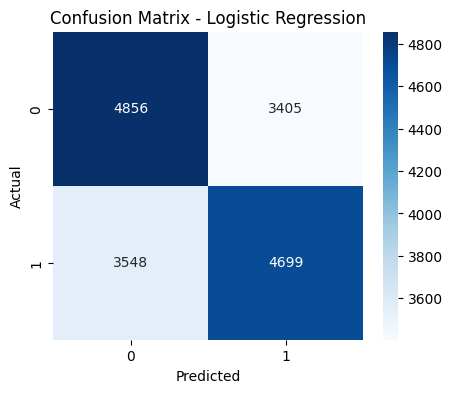

Classification Report: Logistic Regression
              precision    recall  f1-score   support

           0       0.58      0.59      0.58      8261
           1       0.58      0.57      0.57      8247

    accuracy                           0.58     16508
   macro avg       0.58      0.58      0.58     16508
weighted avg       0.58      0.58      0.58     16508



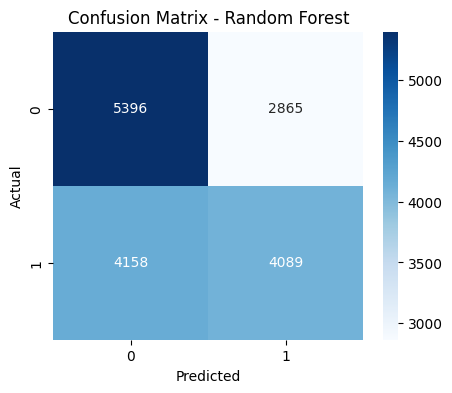

Classification Report: Random Forest
              precision    recall  f1-score   support

           0       0.56      0.65      0.61      8261
           1       0.59      0.50      0.54      8247

    accuracy                           0.57     16508
   macro avg       0.58      0.57      0.57     16508
weighted avg       0.58      0.57      0.57     16508



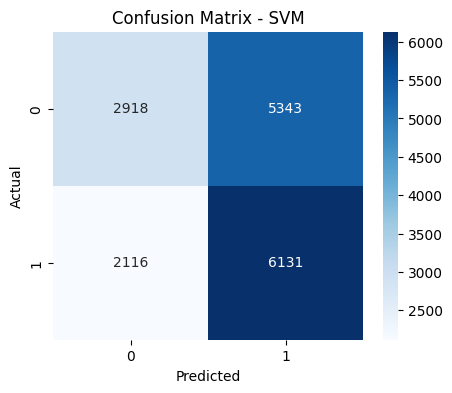

Classification Report: SVM
              precision    recall  f1-score   support

           0       0.58      0.35      0.44      8261
           1       0.53      0.74      0.62      8247

    accuracy                           0.55     16508
   macro avg       0.56      0.55      0.53     16508
weighted avg       0.56      0.55      0.53     16508



C:\Users\sonso\AppData\Local\Temp\ipykernel_17876\3628863196.py:146: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('tab10')


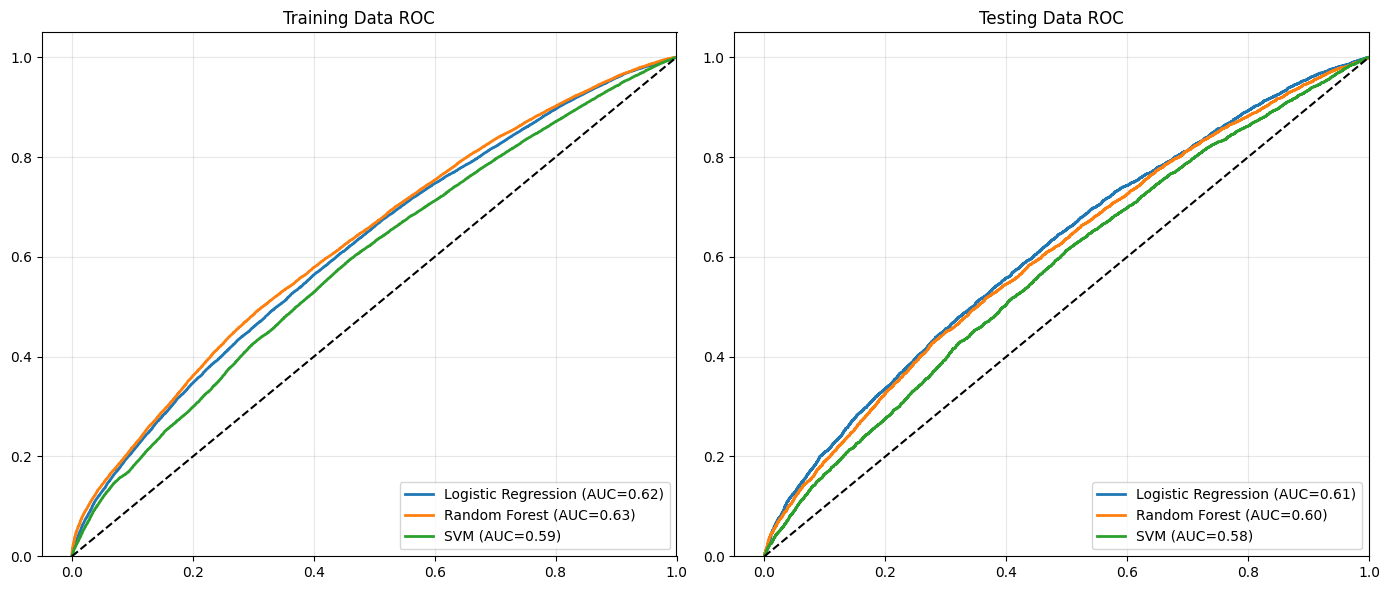

In [36]:
X = x_no_cat
y = y_no_cat

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'accuracy': 'accuracy'}
pipelines = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr_model', LogisticRegression(max_iter=500, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('rf_model', RandomForestClassifier(n_estimators=60, max_depth=4, 
                                            min_samples_leaf=4, n_jobs=-1, random_state=42))
    ]),
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('svm_model', SVC(kernel='rbf', C=0.01, gamma=0.1, random_state=42)) 
    ])
}


results = {}

for model_name, pipeline in pipelines.items():
    print(f"Training {model_name}...")
    cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, 
                                return_train_score=True, return_estimator=True)
    
    results[model_name] = {
        'train_acc_mean': np.mean(cv_results['train_accuracy']),
        'test_acc_mean': np.mean(cv_results['test_accuracy']),
        'train_acc_folds': cv_results['train_accuracy'],
        'test_acc_folds': cv_results['test_accuracy'],
        'estimators': cv_results['estimator'] 
    }



print("="*70)
print("MODEL PERFORMANCE SUMMARY")
print("="*70)
for model_name in results.keys():
    train_acc = results[model_name]['train_acc_folds']
    train_mean = results[model_name]['train_acc_mean']
    test_mean = results[model_name]['test_acc_mean']
    
    print(f"\nModel: {model_name}")
    print(f"Accuracy per fold (train): {np.round(train_acc, 2)}")
    print(f"Train Acc: {train_mean:.4f} ({train_mean*100:.2f}%)")
    print(f"Test Acc:  {test_mean:.4f} ({test_mean*100:.2f}%)")

# Visualization: Feature Importance
print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)
for model_name in results.keys():
    estimators = results[model_name]['estimators']
    all_importances = []
    
    for estimator in estimators:
        if model_name == 'Random Forest':
            imp = estimator.named_steps['rf_model'].feature_importances_
        elif model_name == 'Logistic Regression':
            imp = np.abs(estimator.named_steps['lr_model'].coef_[0])
        elif model_name == 'SVM':
            # SVM RBF kernel doesn't have simple coef_
            continue
            
        all_importances.append(imp)
    
    if all_importances:
        # Average across folds
        avg_importances = np.mean(all_importances, axis=0)
        
        feature_importance_df = pd.DataFrame({
            'Feature': X.columns,
            'Importance': avg_importances
        }).sort_values(by='Importance', ascending=False)
        
        print(f"\n{model_name} - Top 5 Features:")
        print(feature_importance_df.head(5))


plot_data = {}
#Predictions collection
for model_name in results.keys():
    y_true_all = []
    y_pred_all = []
    y_train_score_all = []
    y_train_true_all = []
    y_test_score_all = []
    y_test_true_all = []
    
    estimators = results[model_name]['estimators']
    
    for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X)):
        # Get data for this fold
        X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]
        
        # Get the SAVED estimator
        estimator = estimators[fold_idx]
        
        # Predictions
        y_pred = estimator.predict(X_test_fold)
        y_pred_all.extend(y_pred)
        y_true_all.extend(y_test_fold)
        
        # Scores for ROC (Handle decision_function vs predict_proba)
        model_step = estimator.steps[-1][1]
        if hasattr(model_step, 'decision_function'):
            train_score = estimator.decision_function(X_train_fold)
            test_score = estimator.decision_function(X_test_fold)
        else:
            train_score = estimator.predict_proba(X_train_fold)[:, 1]
            test_score = estimator.predict_proba(X_test_fold)[:, 1]
            
        y_train_score_all.extend(train_score)
        y_train_true_all.extend(y_train_fold)
        y_test_score_all.extend(test_score)
        y_test_true_all.extend(y_test_fold)
        
    plot_data[model_name] = {
        'y_true': y_true_all, 'y_pred': y_pred_all,
        'y_train_true': y_train_true_all, 'y_train_score': y_train_score_all,
        'y_test_true': y_test_true_all, 'y_test_score': y_test_score_all
    }

# Plot Confusion Matrices
for model_name, data in plot_data.items():
    cm_matrix = confusion_matrix(data['y_true'], data['y_pred'])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()
    
    print(f"Classification Report: {model_name}")
    print(classification_report(data['y_true'], data['y_pred']))

# Plot ROC Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colormap = plt.cm.get_cmap('tab10')
colors = {name: colormap(i) for i, name in enumerate(results.keys())}

for model_name, data in plot_data.items():
    c = colors[model_name]
    
    # Train ROC
    fpr, tpr, _ = roc_curve(data['y_train_true'], data['y_train_score'])
    ax1.plot(fpr, tpr, label=f'{model_name} (AUC={auc(fpr, tpr):.2f})', color=c, lw=2)
    
    # Test ROC
    fpr, tpr, _ = roc_curve(data['y_test_true'], data['y_test_score'])
    ax2.plot(fpr, tpr, label=f'{model_name} (AUC={auc(fpr, tpr):.2f})', color=c, lw=2)

ax1.set_title('Training Data ROC')
ax2.set_title('Testing Data ROC')

for ax in fig.axes:
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_xlim([-0.05, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


#### 3.3.2 (Team Based Approach)

##### 3.3.2.1 Transfering Data

In [37]:
# Aggregate team-level data per game
team_data = class_data.groupby(['Data', 'Tm']).agg({

    'Res': 'first',
    'Opp': 'first',
    
    # Basic stats
    'MP': 'sum',
    'PTS': 'sum',
    'FG': 'sum',
    'FGA': 'sum',
    '3P': 'sum',
    '3PA': 'sum',
    'FT': 'sum',
    'FTA': 'sum',
    'ORB': 'sum',
    'DRB': 'sum',
    'TRB': 'sum',
    'AST': 'sum',
    'STL': 'sum',
    'BLK': 'sum',
    'TOV': 'sum',
    'PF': 'sum',
    'GmSc': 'mean',
    'FG%': 'mean',
    '3P%': 'mean',
    'FT%': 'mean',
    'TS%': 'mean',
    'AST/TO': 'mean',
    'Def_Impact': 'mean',
    'Off_Impact': 'mean',
    '3P_Arate': 'mean',
    'FT_Arate': 'mean',
    'Shooting_Freq': 'mean',
    'Volume_Playtime': 'sum'
}).reset_index()


##### 3.3.2.2 Splitting Daat

In [38]:
features_to_drop = ["Data"]
target = 'Res'
categorical_features = ['Tm', 'Opp']

# Approach 1 Drop categorical features
class_data_model_1_team = team_data.drop(columns=features_to_drop+categorical_features)
x_no_cat_team = class_data_model_1_team.drop(columns=[target])
y_no_cat_team = class_data_model_1_team[target]


print("Model 1 (No Categorical) X Shape:", x_no_cat_team.shape)
print("Model 1 (No Categorical) Y Shape:", y_no_cat_team.shape)

# Approach 2 One-Hot Encoding for categorical features
class_data_model_2_team = team_data.drop(columns=features_to_drop)
class_data_model_2_team = pd.get_dummies(class_data_model_2_team, columns=categorical_features, drop_first=True)
x_with_cat_team = class_data_model_2_team.drop(columns=[target])
y_with_cat_team = class_data_model_2_team[target]
print("Model 2 (With Categorical) X Shape:", x_with_cat_team.shape)
print("Model 2 (With Categorical) Y Shape:", y_with_cat_team.shape)

Model 1 (No Categorical) X Shape: (1534, 28)
Model 1 (No Categorical) Y Shape: (1534,)
Model 2 (With Categorical) X Shape: (1534, 86)
Model 2 (With Categorical) Y Shape: (1534,)


##### 3.3.2.3 Encoding

In [39]:
encoder = LabelEncoder()
y_no_cat_team = encoder.fit_transform(y_no_cat_team)
y_with_cat_team = encoder.fit_transform(y_with_cat_team)

##### 3.3.2.4 Hyperparameter Tuning (SVM - Grid Search)

In [40]:
from sklearn.model_selection import GridSearchCV

X_tune = x_no_cat_team
y_tune = y_no_cat_team

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm_model', SVC(random_state=42))
])


param_grid = [
    {
        'svm_model__kernel': ['rbf'],
        'svm_model__C': [0.01, 0.1, 1.0, 10.0],
        'svm_model__gamma': ['scale', 0.001, 0.01, 0.1, 1.0]
    },
    {
        'svm_model__kernel': ['linear'],
        'svm_model__C': [0.01, 0.1, 1.0, 10.0]
    }
]

# Grid Search with TimeSeriesSplit
cv_tune = KFold(n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    svm_pipeline, 
    param_grid, 
    cv=cv_tune, 
    scoring='accuracy',
    n_jobs=-1,
)

print("Starting Grid Search for SVM...")
total_combinations = (len(param_grid[0]['svm_model__kernel']) * len(param_grid[0]['svm_model__C']) * len(param_grid[0]['svm_model__gamma'])) + (len(param_grid[1]['svm_model__kernel']) * len(param_grid[1]['svm_model__C']))
print(f"Total parameter combinations to evaluate: {total_combinations}")

grid_search.fit(X_tune, y_tune)

print("\n" + "="*70)
print("GRID SEARCH RESULTS")
print("="*70)
print(f"\nBest Parameters: {grid_search.best_params_}")



# Compare with original SVM parameters
print("\n" + "="*70)
print("COMPARISON WITH ORIGINAL PARAMETERS")
print("="*70)
print("Original: kernel='rbf', C=0.01, gamma=0.1")
print(f"Optimized: {grid_search.best_params_}")

# Store best estimator for later use
best_svm_model = grid_search.best_estimator_

Starting Grid Search for SVM...
Total parameter combinations to evaluate: 24

GRID SEARCH RESULTS

Best Parameters: {'svm_model__C': 10.0, 'svm_model__kernel': 'linear'}

COMPARISON WITH ORIGINAL PARAMETERS
Original: kernel='rbf', C=0.01, gamma=0.1
Optimized: {'svm_model__C': 10.0, 'svm_model__kernel': 'linear'}

GRID SEARCH RESULTS

Best Parameters: {'svm_model__C': 10.0, 'svm_model__kernel': 'linear'}

COMPARISON WITH ORIGINAL PARAMETERS
Original: kernel='rbf', C=0.01, gamma=0.1
Optimized: {'svm_model__C': 10.0, 'svm_model__kernel': 'linear'}


##### 3.3.2.5 Train (with Optimized SVM)

Using optimized SVM parameters: {'svm_model__C': 10.0, 'svm_model__kernel': 'linear'}

Training Logistic Regression...
Training Random Forest...
Training SVM (Original)...
Training SVM (Original)...
Training SVM (Optimized)...
Training SVM (Optimized)...
MODEL PERFORMANCE SUMMARY

Model: Logistic Regression
Accuracy per fold (train): [0.86 0.87 0.86 0.86 0.86]
Train Acc: 0.8610 (86.10%)
Test Acc:  0.8481 (84.81%)

Model: Random Forest
Accuracy per fold (train): [0.78 0.78 0.79 0.78 0.79]
Train Acc: 0.7832 (78.32%)
Test Acc:  0.7484 (74.84%)

Model: SVM (Original)
Accuracy per fold (train): [0.51 0.5  0.5  0.5  0.5 ]
Train Acc: 0.5046 (50.46%)
Test Acc:  0.4818 (48.18%)

Model: SVM (Optimized)
Accuracy per fold (train): [0.85 0.86 0.86 0.86 0.86]
Train Acc: 0.8600 (86.00%)
Test Acc:  0.8403 (84.03%)

FEATURE IMPORTANCE ANALYSIS

Logistic Regression - Top 5 Features:
   Feature  Importance
3      FGA    2.471512
14     TOV    1.309783
1      PTS    1.260021
12     STL    1.212289
10     

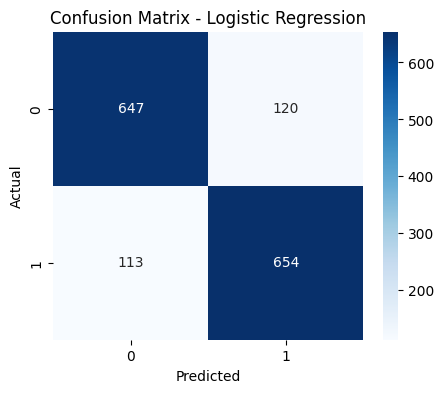

Classification Report: Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.84      0.85       767
           1       0.84      0.85      0.85       767

    accuracy                           0.85      1534
   macro avg       0.85      0.85      0.85      1534
weighted avg       0.85      0.85      0.85      1534



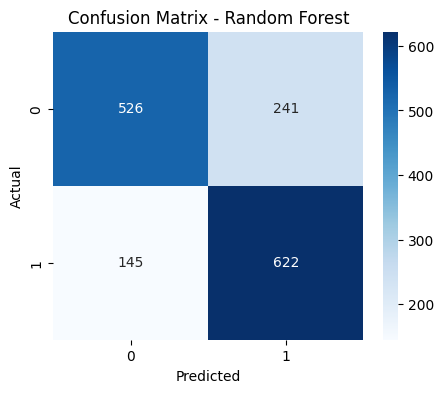

Classification Report: Random Forest
              precision    recall  f1-score   support

           0       0.78      0.69      0.73       767
           1       0.72      0.81      0.76       767

    accuracy                           0.75      1534
   macro avg       0.75      0.75      0.75      1534
weighted avg       0.75      0.75      0.75      1534



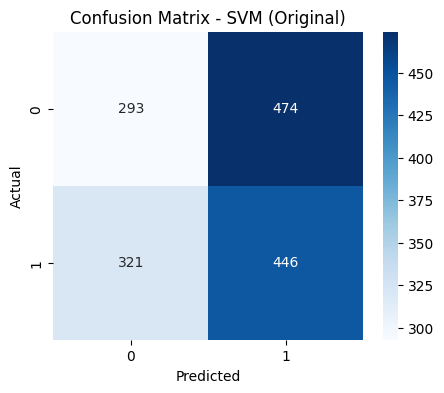

Classification Report: SVM (Original)
              precision    recall  f1-score   support

           0       0.48      0.38      0.42       767
           1       0.48      0.58      0.53       767

    accuracy                           0.48      1534
   macro avg       0.48      0.48      0.48      1534
weighted avg       0.48      0.48      0.48      1534



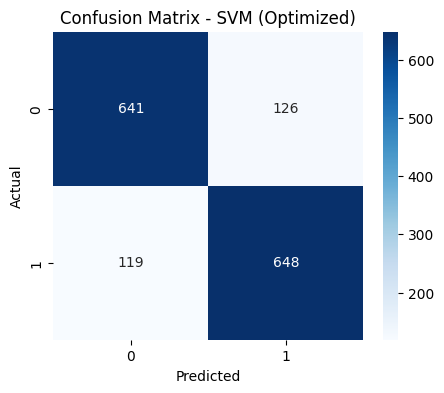

Classification Report: SVM (Optimized)
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       767
           1       0.84      0.84      0.84       767

    accuracy                           0.84      1534
   macro avg       0.84      0.84      0.84      1534
weighted avg       0.84      0.84      0.84      1534



C:\Users\sonso\AppData\Local\Temp\ipykernel_17876\1007403922.py:164: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('tab10')


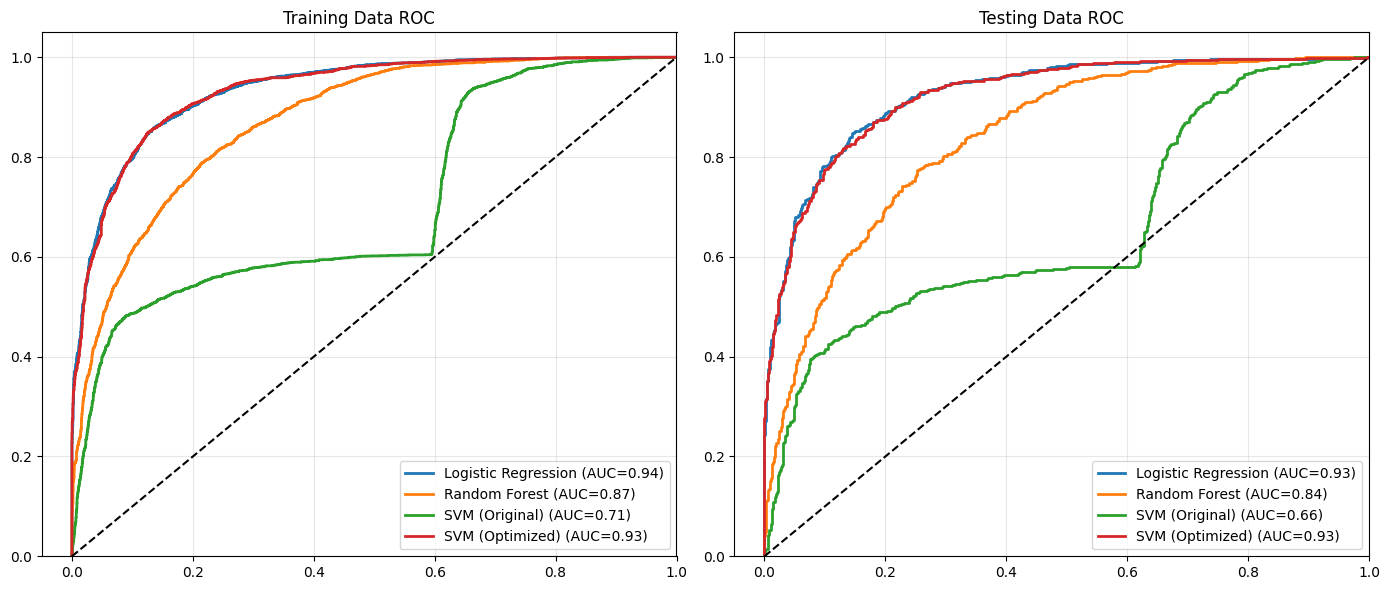

In [41]:
X = x_no_cat_team
y = y_no_cat_team

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'accuracy': 'accuracy'}

# Extract optimized SVM parameters from Grid Search
best_params = grid_search.best_params_
print(f"Using optimized SVM parameters: {best_params}\n")

optimized_svm_params = {
    'kernel': best_params['svm_model__kernel'],
    'C': best_params['svm_model__C'],
    'random_state': 42
}
if best_params['svm_model__kernel'] != 'linear':
    optimized_svm_params['gamma'] = best_params['svm_model__gamma']

pipelines = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr_model', LogisticRegression(max_iter=500, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('rf_model', RandomForestClassifier(n_estimators=60, max_depth=3, 
                                            min_samples_leaf=4, n_jobs=-1, random_state=42))
    ]),
    'SVM (Original)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm_model', SVC(kernel='rbf', C=0.01, gamma=0.1, random_state=42)) 
    ]),
    'SVM (Optimized)': Pipeline([
        ('scaler', StandardScaler()),
        ('svm_model', SVC(**optimized_svm_params))
    ])
}


results = {}

for model_name, pipeline in pipelines.items():
    print(f"Training {model_name}...")
    cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, 
                                return_train_score=True, return_estimator=True)
    
    results[model_name] = {
        'train_acc_mean': np.mean(cv_results['train_accuracy']),
        'test_acc_mean': np.mean(cv_results['test_accuracy']),
        'train_acc_folds': cv_results['train_accuracy'],
        'test_acc_folds': cv_results['test_accuracy'],
        'estimators': cv_results['estimator'] 
    }



print("="*70)
print("MODEL PERFORMANCE SUMMARY")
print("="*70)
for model_name in results.keys():
    train_acc = results[model_name]['train_acc_folds']
    train_mean = results[model_name]['train_acc_mean']
    test_mean = results[model_name]['test_acc_mean']
    
    print(f"\nModel: {model_name}")
    print(f"Accuracy per fold (train): {np.round(train_acc, 2)}")
    print(f"Train Acc: {train_mean:.4f} ({train_mean*100:.2f}%)")
    print(f"Test Acc:  {test_mean:.4f} ({test_mean*100:.2f}%)")

# 5. Visualization: Feature Importance
# ==========================================
print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)
for model_name in results.keys():
    estimators = results[model_name]['estimators']
    all_importances = []
    
    for estimator in estimators:
        # Check model type to get importance/coeffs
        if model_name == 'Random Forest':
            imp = estimator.named_steps['rf_model'].feature_importances_
        elif model_name == 'Logistic Regression':
            imp = np.abs(estimator.named_steps['lr_model'].coef_[0])
        elif model_name == 'SVM':
            continue
            
        all_importances.append(imp)
    
    if all_importances:
        # Average across folds
        avg_importances = np.mean(all_importances, axis=0)
        
        feature_importance_df = pd.DataFrame({
            'Feature': X.columns,
            'Importance': avg_importances
        }).sort_values(by='Importance', ascending=False)
        
        print(f"\n{model_name} - Top 5 Features:")
        print(feature_importance_df.head(5))


plot_data = {}

for model_name in results.keys():
    y_true_all = []
    y_pred_all = []
    y_train_score_all = []
    y_train_true_all = []
    y_test_score_all = []
    y_test_true_all = []
    
    estimators = results[model_name]['estimators']
    
    for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X)):
        # Get data for this fold
        X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]
        
        # Get the SAVED estimator
        estimator = estimators[fold_idx]
        
        # Predictions
        y_pred = estimator.predict(X_test_fold)
        y_pred_all.extend(y_pred)
        y_true_all.extend(y_test_fold)
        
        # Scores for ROC (Handle decision_function vs predict_proba)
        model_step = estimator.steps[-1][1]
        if hasattr(model_step, 'decision_function'):
            train_score = estimator.decision_function(X_train_fold)
            test_score = estimator.decision_function(X_test_fold)
        else:
            train_score = estimator.predict_proba(X_train_fold)[:, 1]
            test_score = estimator.predict_proba(X_test_fold)[:, 1]
            
        y_train_score_all.extend(train_score)
        y_train_true_all.extend(y_train_fold)
        y_test_score_all.extend(test_score)
        y_test_true_all.extend(y_test_fold)
        
    plot_data[model_name] = {
        'y_true': y_true_all, 'y_pred': y_pred_all,
        'y_train_true': y_train_true_all, 'y_train_score': y_train_score_all,
        'y_test_true': y_test_true_all, 'y_test_score': y_test_score_all
    }

#Plot Confusion Matrices
for model_name, data in plot_data.items():
    cm_matrix = confusion_matrix(data['y_true'], data['y_pred'])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()
    
    print(f"Classification Report: {model_name}")
    print(classification_report(data['y_true'], data['y_pred']))

#Plot ROC Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colormap = plt.cm.get_cmap('tab10')
colors = {name: colormap(i) for i, name in enumerate(results.keys())}

for model_name, data in plot_data.items():
    c = colors[model_name]
    
    # Train ROC
    fpr, tpr, _ = roc_curve(data['y_train_true'], data['y_train_score'])
    ax1.plot(fpr, tpr, label=f'{model_name} (AUC={auc(fpr, tpr):.2f})', color=c, lw=2)
    
    # Test ROC
    fpr, tpr, _ = roc_curve(data['y_test_true'], data['y_test_score'])
    ax2.plot(fpr, tpr, label=f'{model_name} (AUC={auc(fpr, tpr):.2f})', color=c, lw=2)

ax1.set_title('Training Data ROC')
ax2.set_title('Testing Data ROC')

for ax in fig.axes:
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_xlim([-0.05, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Training Insights and Comparisons

**MODEL PERFORMANCE & INSIGHTS ANALYSIS**

**1. Executive Summary**
* **Approach 1 (Individual Player-Level Data):** Models demonstrate weak predictive performance (~55-58% accuracy). Individual player statistics lack sufficient signal for reliable win prediction.
* **Approach 2 (Aggregate Team-Based Level):** Dramatic performance improvement with team-level aggregation.  
  * **Best Models:** Logistic Regression (Test Acc = **84.81%**) and Optimized SVM (Test Acc = **84.03%**).  
  * Random Forest shows moderate overfitting (~3.5% train-test gap).
  * Original SVM completely fails (~50% accuracy).

---

**2. Detailed Performance Comparison**

| Model | Scenario | Train Acc | Test Acc | Train-Test Gap | Insight |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Logistic Regression | Individual | 58.16% | 57.88% | 0.28% | Barely better than random. Weak individual-level signal. |
| Random Forest | Individual | 59.20% | 57.46% | 1.74% | Slight overfitting but still poor performance overall. |
| SVM | Individual | 55.27% | 54.82% | 0.45% | Poor class separation at individual level. |
| **Logistic Regression** | **Team-Based** | **86.10%** | **84.81%** | **1.29%** | **Best overall performance.** Excellent generalization. |
| Random Forest | Team-Based | 78.32% | 74.84% | 3.48% | Moderate overfitting—learns team patterns but loses some generalization. |
| SVM (Original) | Team-Based | 50.46% | 48.18% | 2.28% | **Complete failure.** Default hyperparameters ineffective. |
| **SVM (Optimized)** | **Team-Based** | **86.00%** | **84.03%** | **1.97%** | Strong performance after hyperparameter tuning. |

---

**3. Key Observations**

**Impact of Data Aggregation:**
* **Individual Level:** All models struggle (~55-59% accuracy)—barely outperforming random guessing (50%)
* **Team Level:** Performance jumps dramatically (+26-29 percentage points)—aggregation creates stronger predictive signal


**Generalization Quality:**
* **Logistic Regression:** Most stable across both scenarios (0.28% and 1.29% gaps)
* **Random Forest:** Consistently shows overfitting tendency (1.74% individual, 3.48% team-based)
* **SVM:** Extreme sensitivity to hyperparameters—goes from 48.18% (original) to 84.03% (optimized)

---

**4. Feature Importance Analysis**

**Individual Player-Level (Approach 1):**

* **Logistic Regression Top 5:**
  1. `GmSc` (Game Score): 0.482
  2. `FGA` (Field Goal Attempts): 0.399
  3. `FTA` (Free Throw Attempts): 0.198
  4. `MP` (Minutes Played): 0.172
  5. `FT` (Free Throws): 0.171

* **Random Forest Top 5:**
  1. `GmSc` (Game Score): 0.187
  2. `TS%` (True Shooting %): 0.151
  3. `Def_Impact`: 0.095
  4. `FG%` (Field Goal %): 0.091
  5. `MP` (Minutes Played): 0.049

* **Key Insight:** Individual-level models focus on **composite metrics** (GmSc) and **volume statistics** (FGA, FTA) but still can't achieve strong predictions.

---

**Aggregate Team-Based Level (Approach 2):**

* **Logistic Regression Top 5:**
  1. `FGA` (Field Goal Attempts): 2.472
  2. `TOV` (Turnovers): 1.310
  3. `PTS` (Points): 1.260
  4. `STL` (Steals): 1.212
  5. `TRB` (Total Rebounds): 1.166

* **Random Forest Top 5:**
  1. `GmSc` (Game Score): 0.313
  2. `PTS` (Points): 0.132
  3. `DRB` (Defensive Rebounds): 0.107
  4. `FG` (Field Goals): 0.104
  5. `Def_Impact`: 0.078

* **SVM (Both Original & Optimized) Top 5:**
  1. `GmSc` (Game Score): 0.317
  2. `DRB` (Defensive Rebounds): 0.128
  3. `PTS` (Points): 0.123
  4. `FG` (Field Goals): 0.097
  5. `Def_Impact`: 0.074

* **Key Insight:** Team-level models emphasize **scoring efficiency** (PTS, FGA), **possession control** (TOV), **defensive metrics** (STL, DRB, Def_Impact), and **rebounding** (TRB).

---

**5. Model-Specific Insights**

**Logistic Regression:**
* Consistent performer across both approaches
* Minimal overfitting in both scenarios (0.28% and 1.29% gaps)
* At team level, strongly weights `FGA` (2.47)—shooting volume is critical predictor
* Most reliable model for deployment

**Random Forest:**
* Shows persistent overfitting tendency regardless of data level
* Performance degrades more than linear models when moving from train to test
* At team level, relies heavily on `GmSc` composite metric (0.313 importance)
* May be capturing noise in team-specific patterns

**SVM:**
* Extremely hyperparameter-sensitive
* Original configuration completely fails (48.18% test accuracy—worse than random)
* Optimized version achieves competitive performance (84.03%)
* Feature importance pattern similar to Random Forest (both tree-based and kernel methods agree on key features)

---

**6. Conclusions**

1. **Aggregation is Critical:** Moving from individual to team-level data provides a +26-29 percentage point improvement in accuracy
2. **Linear Models Excel:** Logistic Regression achieves best generalization (84.81%) with minimal complexity
3. **Hyperparameters Matter:** SVM demonstrates dramatic sensitivity—proper tuning is essential (48.18% → 84.03%)
4. **Predictive Drivers at Team Level:**
   - **Offensive Volume:** FGA, PTS (shooting and scoring)
   - **Possession Management:** TOV (turnovers hurt win probability)
   - **Defensive Performance:** STL, DRB, Def_Impact
   - **Board Control:** TRB (rebounding advantage)


## 4.0 Unsupervised

### Preparing Data

In [45]:
unsupervised_data = data[data['MP'] > 0].copy()
unsupervised_data = unsupervised_data.groupby('Player').agg({
    'MP': 'mean',
    'PTS': 'mean',
    'FG': 'mean',
    'FGA': 'mean',
    '3P': 'mean',
    '3PA': 'mean',
    'FT': 'mean',
    'FTA': 'mean',
    'ORB': 'mean',
    'DRB': 'mean',
    'TRB': 'mean',
    'AST': 'mean',
    'STL': 'mean',
    'BLK': 'mean',
    'TOV': 'mean',
    'PF': 'mean',
    'GmSc': 'mean',
    'FG%': 'mean',
    '3P%': 'mean',
    'FT%': 'mean'
}).reset_index()
print("Original Data Shape:", data.shape)
print("Unsupervised Data Shape:", unsupervised_data.shape)
print("unsupervised Data columns:", unsupervised_data.columns.tolist())

Original Data Shape: (16512, 25)
Unsupervised Data Shape: (562, 21)
unsupervised Data columns: ['Player', 'MP', 'PTS', 'FG', 'FGA', '3P', '3PA', 'FT', 'FTA', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'GmSc', 'FG%', '3P%', 'FT%']


### Feature Engineering

In [46]:
unsupervised_data['TS%'] = unsupervised_data['PTS'] / (2 * (unsupervised_data['FGA'] + 0.44 * unsupervised_data['FTA']))
unsupervised_data['TS%'] = unsupervised_data['TS%'].fillna(0.0)

unsupervised_data['AST/TO'] = unsupervised_data['AST'] / (unsupervised_data['TOV'] + 1e-10)
unsupervised_data['Def_Impact'] = (unsupervised_data['STL'] + unsupervised_data['BLK'] + unsupervised_data['DRB'])
unsupervised_data['Off_Impact'] = (unsupervised_data['AST'] + unsupervised_data['ORB']) 

unsupervised_data['Usage_Rate'] = (unsupervised_data['FGA'] + 0.44 * unsupervised_data['FTA'] + unsupervised_data['TOV']) 
                                  

### Relevant Features and Scalling

In [47]:

features_to_use = [
    'PTS',     
    'AST',      
    'STL',      
    'BLK',
    'FG%',
    '3P%',
    'FT%',
    'ORB',
    'DRB',
    'Usage_Rate'
]

X_unsupervised = unsupervised_data[features_to_use]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unsupervised)


### Optimal K: Elbow Method, Silhouette Score, and Davies-Bouldin Index

K=2: Inertia=3479.78, Silhouette=0.3353, Davies-Bouldin=1.1780
K=3: Inertia=2777.69, Silhouette=0.2634, Davies-Bouldin=1.3479
K=4: Inertia=2292.69, Silhouette=0.2894, Davies-Bouldin=1.1565
K=5: Inertia=2076.99, Silhouette=0.2231, Davies-Bouldin=1.2902
K=6: Inertia=1902.85, Silhouette=0.2270, Davies-Bouldin=1.3620
K=7: Inertia=1781.09, Silhouette=0.1975, Davies-Bouldin=1.4544
K=8: Inertia=1706.97, Silhouette=0.2030, Davies-Bouldin=1.5208
K=9: Inertia=1588.53, Silhouette=0.2015, Davies-Bouldin=1.4092
K=10: Inertia=1536.68, Silhouette=0.1942, Davies-Bouldin=1.4753


K=2: Inertia=3479.78, Silhouette=0.3353, Davies-Bouldin=1.1780
K=3: Inertia=2777.69, Silhouette=0.2634, Davies-Bouldin=1.3479
K=4: Inertia=2292.69, Silhouette=0.2894, Davies-Bouldin=1.1565
K=5: Inertia=2076.99, Silhouette=0.2231, Davies-Bouldin=1.2902
K=6: Inertia=1902.85, Silhouette=0.2270, Davies-Bouldin=1.3620
K=7: Inertia=1781.09, Silhouette=0.1975, Davies-Bouldin=1.4544
K=8: Inertia=1706.97, Silhouette=0.2030, Davies-Bouldin=1.5208
K=9: Inertia=1588.53, Silhouette=0.2015, Davies-Bouldin=1.4092
K=10: Inertia=1536.68, Silhouette=0.1942, Davies-Bouldin=1.4753


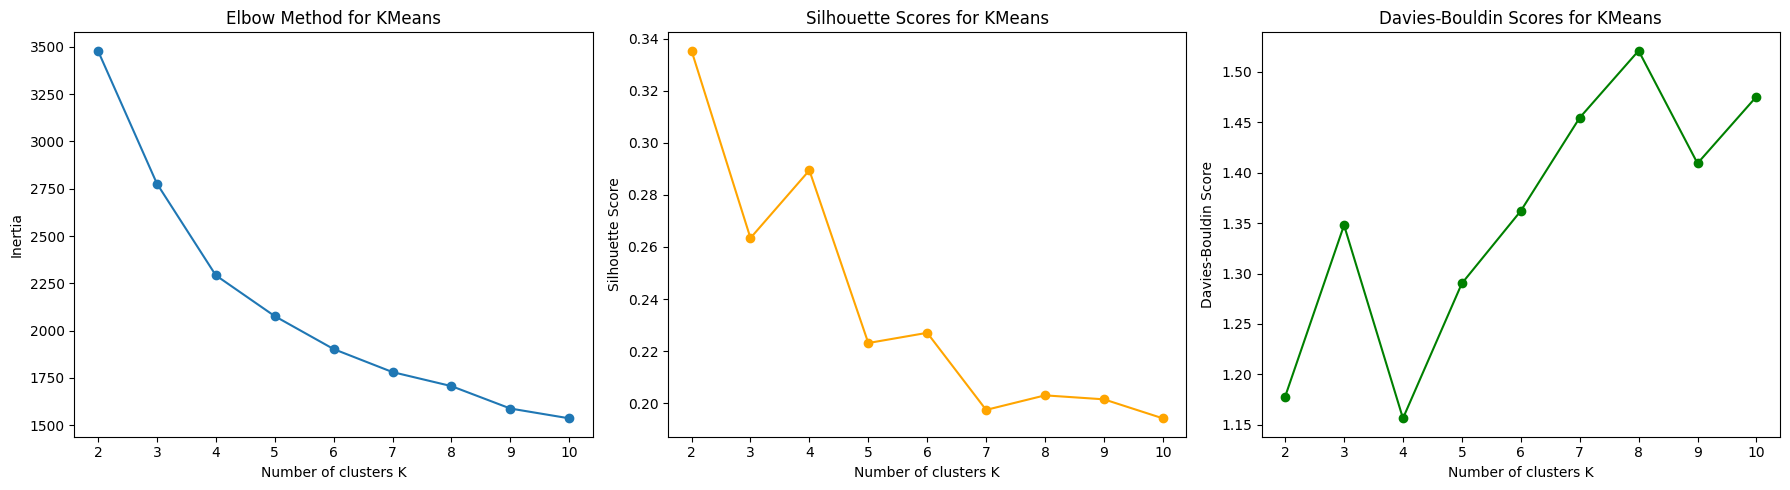

In [49]:
interias = []
shill_scores = []
db_scores = []

K_range = range(2, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    interias.append(kmeans.inertia_)
    shill = silhouette_score(X_scaled, cluster_labels)
    shill_scores.append(shill)
    db = davies_bouldin_score(X_scaled, cluster_labels)
    db_scores.append(db)
    print(f"K={k}: Inertia={kmeans.inertia_:.2f}, Silhouette={shill:.4f}, Davies-Bouldin={db:.4f}")
# Plotting the metrics
# Elbow Method for Inertia
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(K_range, interias, marker='o', linestyle='-')
axes[0].set_title('Elbow Method for KMeans')
axes[0].set_xlabel('Number of clusters K')
axes[0].set_ylabel('Inertia')
# Silhouette Scores
axes[1].plot(K_range, shill_scores, marker='o', linestyle='-', color='orange')
axes[1].set_title('Silhouette Scores for KMeans')
axes[1].set_xlabel('Number of clusters K')
axes[1].set_ylabel('Silhouette Score')
# Davies-Bouldin Scores
axes[2].plot(K_range, db_scores, marker='o', linestyle='-', color='green')
axes[2].set_title('Davies-Bouldin Scores for KMeans')
axes[2].set_xlabel('Number of clusters K')
axes[2].set_ylabel('Davies-Bouldin Score')
plt.tight_layout()
plt.show()




**Optimal K Found = 4**

### K-Means

In [50]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

shill = silhouette_score(X_scaled, cluster_labels)
db = davies_bouldin_score(X_scaled, cluster_labels)
print(f"\nFinal Clustering with K=4: Silhouette={shill:.4f}, Davies-Bouldin={db:.4f}")


Final Clustering with K=4: Silhouette=0.2886, Davies-Bouldin=1.1699


### Hierarchical (Agglomerative)


In [51]:
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)
shill_agg = silhouette_score(X_scaled, agg_labels)
db_agg = davies_bouldin_score(X_scaled, agg_labels)
print(f"Agglomerative Clustering with K=4: Silhouette={shill_agg:.4f}, Davies-Bouldin={db_agg:.4f}")


Agglomerative Clustering with K=4: Silhouette=0.2629, Davies-Bouldin=1.1778


### Identifying and Interpreting Clusters (k mean)

CLUSTER CHARACTERISTICS SUMMARY
           PTS   AST   TRB   STL   BLK   FG%   3P%   FT%     MP   TOV  \
Cluster                                                                 
0         2.39  0.60  1.31  0.23  0.14  0.27  0.13  0.14   7.51  0.38   
1         8.35  1.99  3.25  0.78  0.33  0.42  0.31  0.36  20.98  1.01   
2        20.00  4.78  5.70  1.14  0.56  0.46  0.35  0.70  32.58  2.39   
3         9.82  1.71  7.43  0.75  1.14  0.54  0.11  0.46  23.26  1.21   

         Def_Impact  Off_Impact   TS%   GmSc  Count  
Cluster                                              
0              1.31        0.98  0.48   1.82    183  
1              3.55        2.80  0.56   6.64    216  
2              6.25        5.93  0.58  15.57    103  
3              6.95        4.08  0.60   9.91     60  


CLUSTER CHARACTERISTICS SUMMARY
           PTS   AST   TRB   STL   BLK   FG%   3P%   FT%     MP   TOV  \
Cluster                                                                 
0         2.39  0.60  1.31  0.23  0.14  0.27  0.13  0.14   7.51  0.38   
1         8.35  1.99  3.25  0.78  0.33  0.42  0.31  0.36  20.98  1.01   
2        20.00  4.78  5.70  1.14  0.56  0.46  0.35  0.70  32.58  2.39   
3         9.82  1.71  7.43  0.75  1.14  0.54  0.11  0.46  23.26  1.21   

         Def_Impact  Off_Impact   TS%   GmSc  Count  
Cluster                                              
0              1.31        0.98  0.48   1.82    183  
1              3.55        2.80  0.56   6.64    216  
2              6.25        5.93  0.58  15.57    103  
3              6.95        4.08  0.60   9.91     60  


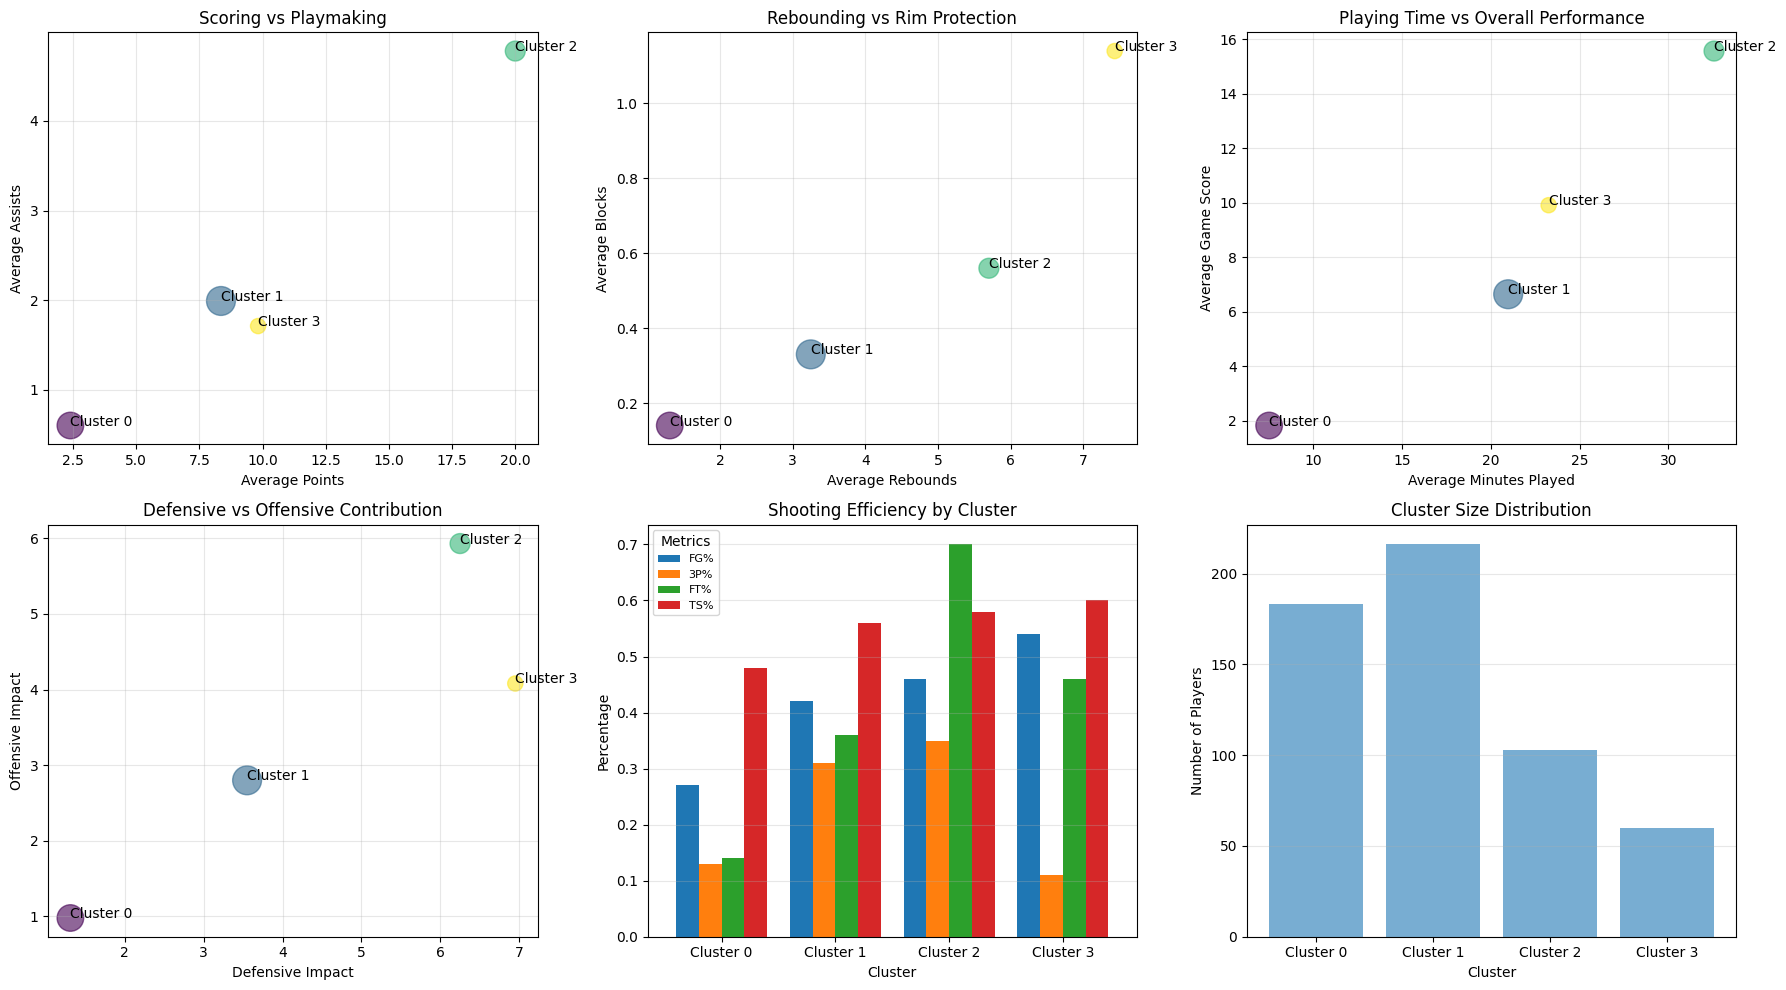

In [52]:

best_labels = cluster_labels  

cluster_data = unsupervised_data.copy()
cluster_data['Cluster'] = best_labels

# Analyze cluster characteristics by computing mean values
cluster_summary = cluster_data.groupby('Cluster').agg({
    'PTS': 'mean',
    'AST': 'mean',
    'TRB': 'mean',
    'STL': 'mean',
    'BLK': 'mean',
    'FG%': 'mean',
    '3P%': 'mean',
    'FT%': 'mean',
    'MP': 'mean',
    'TOV': 'mean',
    'Def_Impact': 'mean',
    'Off_Impact': 'mean',
    'TS%': 'mean',
    'GmSc': 'mean'
}).round(2)

cluster_summary['Count'] = cluster_data.groupby('Cluster').size()

print("="*80)
print("CLUSTER CHARACTERISTICS SUMMARY")
print("="*80)
print(cluster_summary)

# Visualize key characteristics
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Plot 1: Points vs Assists
axes[0, 0].scatter(cluster_summary['PTS'], cluster_summary['AST'], 
                   s=cluster_summary['Count']*2, alpha=0.6, c=range(len(cluster_summary)))
for i, txt in enumerate(cluster_summary.index):
    axes[0, 0].annotate(f'Cluster {txt}', (cluster_summary['PTS'].iloc[i], cluster_summary['AST'].iloc[i]))
axes[0, 0].set_xlabel('Average Points')
axes[0, 0].set_ylabel('Average Assists')
axes[0, 0].set_title('Scoring vs Playmaking')
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Rebounds vs Blocks
axes[0, 1].scatter(cluster_summary['TRB'], cluster_summary['BLK'], 
                   s=cluster_summary['Count']*2, alpha=0.6, c=range(len(cluster_summary)))
for i, txt in enumerate(cluster_summary.index):
    axes[0, 1].annotate(f'Cluster {txt}', (cluster_summary['TRB'].iloc[i], cluster_summary['BLK'].iloc[i]))
axes[0, 1].set_xlabel('Average Rebounds')
axes[0, 1].set_ylabel('Average Blocks')
axes[0, 1].set_title('Rebounding vs Rim Protection')
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Minutes Played vs Game Score
axes[0, 2].scatter(cluster_summary['MP'], cluster_summary['GmSc'], 
                   s=cluster_summary['Count']*2, alpha=0.6, c=range(len(cluster_summary)))
for i, txt in enumerate(cluster_summary.index):
    axes[0, 2].annotate(f'Cluster {txt}', (cluster_summary['MP'].iloc[i], cluster_summary['GmSc'].iloc[i]))
axes[0, 2].set_xlabel('Average Minutes Played')
axes[0, 2].set_ylabel('Average Game Score')
axes[0, 2].set_title('Playing Time vs Overall Performance')
axes[0, 2].grid(True, alpha=0.3)

# Plot 4: Defensive vs Offensive Impact
axes[1, 0].scatter(cluster_summary['Def_Impact'], cluster_summary['Off_Impact'], 
                   s=cluster_summary['Count']*2, alpha=0.6, c=range(len(cluster_summary)))
for i, txt in enumerate(cluster_summary.index):
    axes[1, 0].annotate(f'Cluster {txt}', (cluster_summary['Def_Impact'].iloc[i], cluster_summary['Off_Impact'].iloc[i]))
axes[1, 0].set_xlabel('Defensive Impact')
axes[1, 0].set_ylabel('Offensive Impact')
axes[1, 0].set_title('Defensive vs Offensive Contribution')
axes[1, 0].grid(True, alpha=0.3)

# Plot 5: Shooting Efficiency
shooting_metrics = cluster_summary[['FG%', '3P%', 'FT%', 'TS%']]
shooting_metrics.plot(kind='bar', ax=axes[1, 1], width=0.8)
axes[1, 1].set_xlabel('Cluster')
axes[1, 1].set_ylabel('Percentage')
axes[1, 1].set_title('Shooting Efficiency by Cluster')
axes[1, 1].legend(title='Metrics', fontsize=8)
axes[1, 1].set_xticklabels([f'Cluster {i}' for i in cluster_summary.index], rotation=0)
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Plot 6: Cluster Size Distribution
axes[1, 2].bar(range(len(cluster_summary)), cluster_summary['Count'], alpha=0.6)
axes[1, 2].set_xlabel('Cluster')
axes[1, 2].set_ylabel('Number of Players')
axes[1, 2].set_title('Cluster Size Distribution')
axes[1, 2].set_xticks(range(len(cluster_summary)))
axes[1, 2].set_xticklabels([f'Cluster {i}' for i in cluster_summary.index])
axes[1, 2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [53]:
# After analyzing, assign names to clusters
cluster_names = {
    0: "Bench Players / Role Players", #Low MP, Low GmSc
    1: "Starters / All-Rounders", # Average MP, Balanced Stats Good in evrything 
    2: "Star Players / Elite Scorers", # High PTS, High MP, high GmSc, assists, TOP PLAYERS
    3: "Defensive Specialists"  # High Def_Impact, lower PTS, lower AST
}

cluster_data['Cluster_Name'] = cluster_data['Cluster'].map(cluster_names)

# Display sample players from each cluster
print("\n" + "="*80)
print("SAMPLE PLAYERS FROM EACH CLUSTER")
print("="*80)
for cluster_id, cluster_name in cluster_names.items():
    print(f"\n{cluster_name} (Cluster {cluster_id}):")
    sample_players = cluster_data[cluster_data['Cluster'] == cluster_id][['Player', 'PTS', 'AST', 'TRB', 'MP', 'GmSc']].head(5)
    print(sample_players.to_string(index=False))


SAMPLE PLAYERS FROM EACH CLUSTER

Bench Players / Role Players (Cluster 0):
       Player      PTS      AST      TRB        MP     GmSc
   AJ Johnson 2.444444 1.222222 1.000000  6.022222 1.633333
Aaron Holiday 4.222222 1.194444 0.944444 11.371944 3.097222
 Adam Flagler 1.263158 0.000000 0.421053  4.278421 0.010526
 Adama Sanogo 2.000000 0.250000 1.500000  5.372500 1.950000
    Adem Bona 3.000000 0.305556 2.833333 10.940278 2.930556

Starters / All-Rounders (Cluster 1):
       Player       PTS      AST      TRB        MP      GmSc
   A.J. Green  7.659091 1.272727 2.250000 21.997500  5.404545
  A.J. Lawson  2.750000 0.000000 0.750000  3.757500  1.875000
 Aaron Gordon 12.333333 3.066667 4.733333 26.666000 10.696667
Aaron Nesmith  8.200000 1.266667 3.333333 20.949333  6.426667
Aaron Wiggins 10.137255 1.568627 3.568627 21.322745  8.172549

Star Players / Elite Scorers (Cluster 2):
         Player       PTS      AST       TRB        MP      GmSc
 Alperen Sengun 18.771429 5.000000 10.457143 

### Visualize Clusters (PCA vs t-SNE)

PCA Variance Explained:
  PC1: 57.42%
  PC2: 17.02%
  Total: 74.44%



PCA Variance Explained:
  PC1: 57.42%
  PC2: 17.02%
  Total: 74.44%



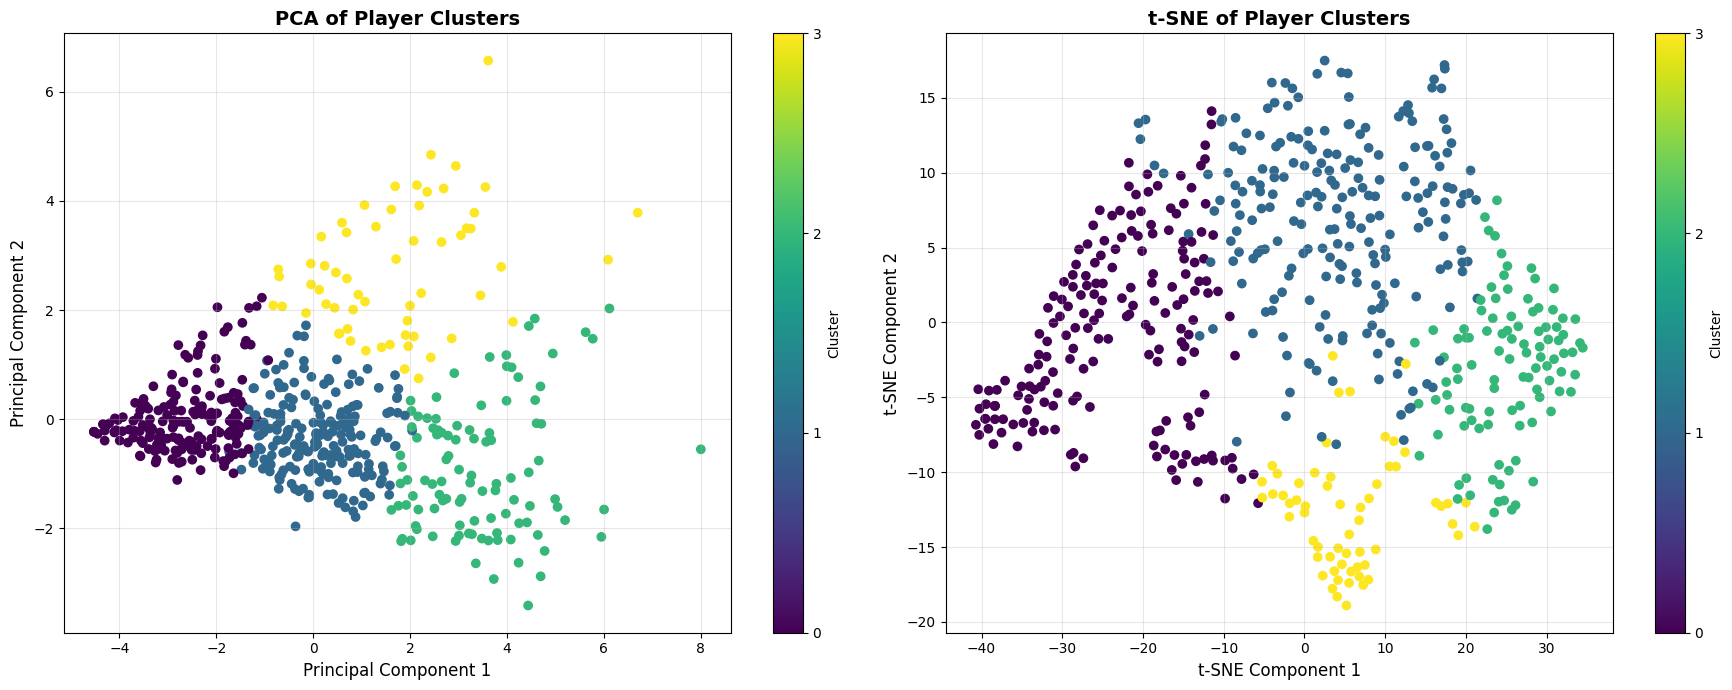

In [54]:
# Apply PCA and t-SNE for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

variance_explained = pca.explained_variance_ratio_
print(f"PCA Variance Explained:")
print(f"  PC1: {variance_explained[0]*100:.2f}%")
print(f"  PC2: {variance_explained[1]*100:.2f}%")
print(f"  Total: {variance_explained.sum()*100:.2f}%\n")

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# PCA Plot
scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=best_labels, cmap='viridis')
ax1.set_title('PCA of Player Clusters', fontsize=14, fontweight='bold')
ax1.set_xlabel('Principal Component 1', fontsize=12)
ax1.set_ylabel('Principal Component 2', fontsize=12)
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=ax1, ticks=range(len(cluster_names)), label='Cluster')

# t-SNE Plot
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=best_labels, cmap='viridis')
ax2.set_title('t-SNE of Player Clusters', fontsize=14, fontweight='bold')
ax2.set_xlabel('t-SNE Component 1', fontsize=12)
ax2.set_ylabel('t-SNE Component 2', fontsize=12)
ax2.grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=ax2, ticks=range(len(cluster_names)), label='Cluster')

plt.tight_layout()
plt.show()

## 5.0 Open Ended Task (Anomaly Detection & Outlier Analysis)

### 5.1 DBSCAN Clustering for Outlier Detection


In [110]:

dbscan = DBSCAN(eps=2, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Count outliers (label = -1)
n_outliers_dbscan = (dbscan_labels == -1).sum()

print(f"DBSCAN Results:")
print(f"  Number of outliers (noise points): {n_outliers_dbscan}")
print(f"  Percentage of outliers: {n_outliers_dbscan/len(dbscan_labels)*100:.2f}%")



DBSCAN Results:
  Number of outliers (noise points): 25
  Percentage of outliers: 4.45%


### 5.2 Statistical Outlier Detection (Z-Score Method)
Detect outliers using Z-scores on key performance metrics. Points with |Z-score| > 3 are considered outliers.

In [111]:
# Calculate Z-scores for key metrics (uses original unsupervised_data, not scaled)
key_metrics = ['PTS', 'GmSc', 'TS%', 'MP']
z_scores = np.abs(stats.zscore(unsupervised_data[key_metrics].fillna(0)))

# Identify outliers (any metric with |Z| > 3)
outlier_mask_zscore = (z_scores > 3).any(axis=1)
n_outliers_zscore = outlier_mask_zscore.sum()

print(f"\nZ-Score Outlier Detection:")
print(f"  Number of outliers: {n_outliers_zscore}")
print(f"  Percentage of outliers: {n_outliers_zscore/len(unsupervised_data)*100:.2f}%")

# Show which metrics triggered outlier detection
outlier_players_zscore = unsupervised_data[outlier_mask_zscore].copy()
print(f"\n  Metrics causing outlier detection:")
for i, metric in enumerate(key_metrics):
    metric_outliers = (z_scores[:, i] > 3).sum()
    print(f"    {metric}: {metric_outliers} players")


Z-Score Outlier Detection:
  Number of outliers: 21
  Percentage of outliers: 3.74%

  Metrics causing outlier detection:
    PTS: 3 players
    GmSc: 3 players
    TS%: 18 players
    MP: 0 players


### 5.3 Machine Learning-Based Outlier Detection
Using Isolation Forest and Local Outlier Factor (LOF) to detect anomalous player profiles.

In [ ]:
# Isolation Forest (uses X_scaled for distance-based anomaly detection)
iso_forest = IsolationForest(contamination=0.05, random_state=42)
outlier_labels_iso = iso_forest.fit_predict(X_scaled)
n_outliers_iso = (outlier_labels_iso == -1).sum()

print(f"\nIsolation Forest Outlier Detection:")
print(f"  Number of outliers: {n_outliers_iso}")
print(f"  Percentage of outliers: {n_outliers_iso/len(X_scaled)*100:.2f}%")

# Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
outlier_labels_lof = lof.fit_predict(X_scaled)
n_outliers_lof = (outlier_labels_lof == -1).sum()

print(f"\nLocal Outlier Factor (LOF) Detection:")
print(f"  Number of outliers: {n_outliers_lof}")
print(f"  Percentage of outliers: {n_outliers_lof/len(X_scaled)*100:.2f}%")

# Create outlier dataset
unsupervised_data['DBSCAN_Outlier'] = dbscan_labels == -1
unsupervised_data['ZScore_Outlier'] = outlier_mask_zscore
unsupervised_data['IsoForest_Outlier'] = outlier_labels_iso == -1
unsupervised_data['LOF_Outlier'] = outlier_labels_lof == -1

# Count how many methods flagged each player
unsupervised_data['Outlier_Count'] = (
    unsupervised_data['DBSCAN_Outlier'].astype(int) +
    unsupervised_data['ZScore_Outlier'].astype(int) +
    unsupervised_data['IsoForest_Outlier'].astype(int) +
    unsupervised_data['LOF_Outlier'].astype(int)
)

print(f"\n{'='*60}")
print("OUTLIER DETECTION SUMMARY")
print(f"{'='*60}")
print(f"Players flagged by all 4 methods: {(unsupervised_data['Outlier_Count'] == 4).sum()}")
print(f"Players flagged by 3 methods: {(unsupervised_data['Outlier_Count'] == 3).sum()}")
print(f"Players flagged by 2 methods: {(unsupervised_data['Outlier_Count'] == 2).sum()}")
print(f"Players flagged by 1 method: {(unsupervised_data['Outlier_Count'] == 1).sum()}")


Isolation Forest Outlier Detection:
  Number of outliers: 29
  Percentage of outliers: 5.16%

Local Outlier Factor (LOF) Detection:
  Number of outliers: 29
  Percentage of outliers: 5.16%

OUTLIER DETECTION SUMMARY
Players flagged by all 4 methods: 5
Players flagged by 3 methods: 11
Players flagged by 2 methods: 8
Players flagged by 1 method: 35


### 5.4 Analyze High-Confidence Outliers


In [ ]:
# High-confidence outliers (flagged by 3+ methods)
high_conf_outliers = unsupervised_data[unsupervised_data['Outlier_Count'] >= 3].copy()

print(f"\n{'='*80}")
print(f"HIGH-CONFIDENCE OUTLIERS (Flagged by 3+ methods): {len(high_conf_outliers)} players")
print(f"{'='*80}\n")

if len(high_conf_outliers) > 0:
    # Display top outliers with key stats
    display_cols = ['Player', 'PTS', 'AST', 'TRB', 'MP', 'GmSc', 'TS%', 'Outlier_Count']
    print(high_conf_outliers[display_cols].sort_values('Outlier_Count', ascending=False).head(15).to_string(index=False))
    
    # Analyze why they're outliers
    print(f"\n{'='*80}")
    print("OUTLIER CHARACTERISTICS ANALYSIS")
    print(f"{'='*80}")
    
    # Compare outliers vs normal players
    normal_players = unsupervised_data[unsupervised_data['Outlier_Count'] == 0]
    
    comparison_metrics = ['PTS', 'AST', 'TRB', 'MP', 'GmSc', 'TS%']
    print(f"\n{'Metric':<10} {'Outliers Mean':<15} {'Normal Mean':<15} {'Difference':<15}")
    print("-" * 60)
    
    for metric in comparison_metrics:
        outlier_mean = high_conf_outliers[metric].mean()
        normal_mean = normal_players[metric].mean()
        diff = outlier_mean - normal_mean
        print(f"{metric:<10} {outlier_mean:>14.2f} {normal_mean:>14.2f} {diff:>14.2f}")
else:
    print("No high-confidence outliers found.")


HIGH-CONFIDENCE OUTLIERS (Flagged by 3+ methods): 16 players

                 Player       PTS       AST       TRB        MP      GmSc      TS%  Outlier_Count
             Alex Reese  2.000000  0.000000  1.000000  1.880000  2.400000 1.000000              4
       Alondes Williams  5.000000  1.000000  0.000000  3.720000  5.100000 1.250000              4
        Daeqwon Plowden 12.000000  0.000000  2.500000 16.360000  9.950000 1.102941              4
  Giannis Antetokounmpo 31.619048  5.976190 12.333333 34.945476 26.376190 0.617996              4
           Nikola Jokić 29.695652 10.326087 12.695652 36.232174 30.567391 0.661565              4
       Domantas Sabonis 20.395833  6.333333 14.270833 35.985208 20.695833 0.671210              3
      Jarred Vanderbilt  3.500000  1.500000  6.833333 15.716667  6.383333 0.531377              3
       Jabari Smith Jr. 12.000000  0.000000  2.000000 22.830000  9.300000 0.675676              3
     Karl-Anthony Towns 24.326087  3.326087 13.608696 3

# Contribution

This woNone By:

1. Hassan Mohamed
2. Abdulah Al- Nofal
3. Yousef Abu-Ghali